# Bagian B – SigLIP Embedding Probe (Ekstrak Sekali → Train Head Cepat)

**Checkpoint:** `google/siglip-so400m-patch14-384`

## Alur (2 tahap)

```
TAHAP 1 – dijalankan SEKALI (lambat, butuh GPU)
  gambar → [augmentasi] → SigLIP (dibekukan, fp16) → embedding 1152-dim → embeddings_{split}.npz  (di Drive)

TAHAP 2 – bisa diulang berkali-kali (hitungan detik/menit per run)
  embeddings_{split}.npz → load → train head → evaluasi
  (ganti/bandingkan arsitektur: linear, MLP, MLP+norm, MLP 2 tahap, ResMLP, kNN, SVM, LightGBM, ensemble)
```

Kenapa lebih cepat dari notebook sebelumnya: di notebook lama, **setiap epoch** semua gambar dibaca ulang,
diaugmentasi, lalu dilewatkan ke backbone SigLIP (~400M parameter) walaupun backbone dibekukan. Di sini backbone
hanya dipakai **satu kali per gambar**; training head bekerja di atas vektor 1152-dim yang sudah tersimpan.

### Perubahan v2 (metodologi, generalisasi, kebersihan data)

| Area | Perubahan | Alasan |
|---|---|---|
| Class weight | `CLASS_WEIGHT_MODE='effective'`: rumus `N/(C*N_c)` dihitung dari jumlah **baris** train `.npz` | `N_AUG` B3=5 vs 2 sudah oversampling ~2x; bobot json (dari jumlah gambar) membuat B3 dikompensasi dobel |
| Loss | default CrossEntropy + label smoothing 0.05 (Focal opsional, bug `pt` berbobot diperbaiki) | Focal memperbesar bobot sampel sulit = termasuk sampel salah label |
| Regularisasi | Mixup di ruang embedding (`MIXUP_ALPHA`) | batas kelas lebih halus, generalisasi lebih baik |
| Diagnostik data | Cell 12b/12c: OOF `StratifiedGroupKFold` (group `orig_idx`), confident learning + kNN, near-duplicate lintas split, outlier centroid | data cleaning dari **train**, bukan dari test |
| Evaluasi jujur | kolom `macro_F1_nodup` (val tanpa near-duplicate train) + macro F1 OOF | skor val tidak digelembungkan oleh duplikat mirip |
| Test | `mark_test_use()` memperingatkan bila test dipakai > 1 model; error analysis dipindah ke **val** | aturan "test disentuh sekali" |
| SVM | C dipilih dari `SVM_C_GRID` via macro F1 val; ensemble lintas keluarga (MLP seed + kNN + SVM) | |

**Prasyarat:** sudah menjalankan preprocessing (`train.csv`, `val.csv`, `test.csv`, `class_weights.json`) dan upload ke Google Drive.


---
## CELL 1 – Mount Google Drive


In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print('[OK] Google Drive berhasil di-mount.')


Mounted at /content/drive
[OK] Google Drive berhasil di-mount.


---
## CELL 2 – Konfigurasi Utama


In [2]:
import os

# ============================================================
# KONFIGURASI – sesuaikan ROOT_DIR dengan lokasi upload Anda
# ============================================================
ROOT_DIR    = '/content/drive/MyDrive/Senpro'
DATASET_DIR = os.path.join(ROOT_DIR, 'Dataset')
OUTPUT_DIR  = os.path.join(ROOT_DIR, 'preprocessing_output')

TRAIN_CSV = os.path.join(OUTPUT_DIR, 'train.csv')
VAL_CSV   = os.path.join(OUTPUT_DIR, 'val.csv')
TEST_CSV  = os.path.join(OUTPUT_DIR, 'test.csv')
CW_JSON   = os.path.join(OUTPUT_DIR, 'class_weights.json')

# Label mapping (sama seperti notebook sebelumnya)
LABEL_TO_IDX = {'Recylable': 0, 'Organik': 1, 'B3': 2}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}
NUM_CLASSES  = len(LABEL_TO_IDX)

RANDOM_SEED = 42

# ------------------------------------------------------------
# TAHAP 1 – Ekstraksi embedding (SigLIP, dijalankan sekali)
# ------------------------------------------------------------
MODEL_CHECKPOINT = 'google/siglip-so400m-patch14-384'
IMAGE_SIZE       = 384

N_AUG = {'Recylable': 2, 'Organik': 2, 'B3': 5}  # jumlah versi TER-AUGMENTASI per gambar train per kelas
                             # total baris train di .npz = jumlah_gambar x (1 + N_AUG). Set 0 = tanpa augmentasi.
BATCH_SIZE_EKSTRAKSI = 32    # jumlah gambar per batch (tiap gambar diproses (1 + N_AUG) view). Turunkan jika OOM.
NUM_WORKERS_EKSTRAKSI = min(8, (os.cpu_count() or 2) * 2)   # Colab gratis biasanya 2 CPU -> 4 worker
USE_FP16         = True      # backbone dijalankan fp16 (lebih cepat & hemat VRAM), hanya untuk ekstraksi
MAX_SISI_GAMBAR  = 1024      # gambar lebih besar dari ini di-downsize dulu (hemat RAM/CPU)
CHUNK_IMAGES     = 1024      # simpan hasil sementara tiap N gambar -> aman kalau Colab disconnect

# Smoke test: set mis. 30 untuk mencoba seluruh alur dengan sedikit gambar per kelas.
# Hasilnya masuk folder terpisah (suffix _debug) sehingga tidak tercampur dengan hasil asli.
DEBUG_MAX_PER_CLASS = None

MODEL_TAG     = MODEL_CHECKPOINT.split('/')[-1]
n_aug_str = f"{N_AUG['Recylable']}_{N_AUG['Organik']}_{N_AUG['B3']}" if isinstance(N_AUG, dict) else str(N_AUG)
EMBEDDING_DIR = os.path.join(ROOT_DIR, 'embeddings', f'{MODEL_TAG}_naug_{n_aug_str}')
if DEBUG_MAX_PER_CLASS:
    EMBEDDING_DIR += '_debug'

# ------------------------------------------------------------
# TAHAP 2 – Training head di atas embedding
# ------------------------------------------------------------
RUN_NAME          = 'mlp_head_v2_ce_ls_mixup'   # ganti nama tiap kali mencoba konfigurasi baru -> hasil lama tidak tertimpa
HEAD_BATCH_SIZE   = 256
HEAD_EPOCHS       = 60
HEAD_LR           = 1e-3
HEAD_WEIGHT_DECAY = 1e-4
DROPOUT_RATE      = 0.3
INPUT_NORM        = 'standardize'   # 'none' | 'l2' | 'standardize' (statistik dihitung dari train saja)

# Arsitektur head
HEAD_TYPE = 'mlp'            # untuk training SATU head (Cell 13): 'linear' | 'mlp' | 'mlp_norm' | 'mlp2' | 'resmlp'
HEAD_ACT  = 'gelu'           # 'gelu' | 'silu'

# Perbandingan banyak head (Cell 16–19)
HEADS_TO_COMPARE = ['linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp']
ENSEMBLE_SEEDS   = [42, 43, 44, 45, 46]   # untuk ensemble beberapa seed dari head terbaik
KNN_K, KNN_TEMP  = 15, 0.05               # kNN cosine: jumlah tetangga, temperature bobot
SVM_C_GRID       = [1.0, 3.0, 10.0]       # SVM RBF: C dipilih via macro F1 VAL (tiap C beberapa menit di CPU)
SVM_MAX_ROWS     = None                   # None = semua baris view asli (~jumlah gambar train); isi angka untuk mempercepat
LGBM_MAX_TREES   = 400                    # LightGBM (early stopping pada val)

USE_FOCAL_LOSS  = False           # v2: CE + label smoothing. Focal memperbesar bobot sampel "sulit",
                                  #     termasuk sampel salah label -> rawan menghafal noise. True = Focal Loss.
FOCAL_GAMMA     = 2.0
LABEL_SMOOTHING = 0.05            # 0 = mati. Membuat head tidak terlalu yakin -> lebih tahan label noise

# ── v2: metodologi & generalisasi ──────────────────────────────
CLASS_WEIGHT_MODE = 'effective'   # 'preprocessing' = class_weights.json apa adanya (dari jumlah GAMBAR)
                                  # 'effective'     = rumus sama N/(C*N_c) tetapi dari jumlah BARIS train .npz.
                                  #   N_AUG B3=5 vs 2 sudah oversampling B3 ~2x; tanpa koreksi B3 dikompensasi dobel
                                  #   (risiko B3 over-trigger / precision B3 turun).
MIXUP_ALPHA       = 0.2           # mixup di ruang embedding (0 = mati)

# Data cleaning (Cell 12b/12c). Kandidat hanya DILAPORKAN; keputusan manual.
CV_FOLDS     = 5                  # StratifiedGroupKFold, group = orig_idx (view augmentasi tidak bocor antar fold)
OOF_HEAD     = 'mlp'              # head untuk prediksi out-of-fold
OOF_EPOCHS   = 20
NEAR_DUP_COS = 0.97               # ambang cosine (standardize + L2) near-duplicate lintas split
# CSV hasil REVIEW MANUAL (mis. label_noise_candidates.csv yang kolom 'keputusan'-nya sudah diisi
# 'buang' / 'relabel:<Kelas>'). Hanya membuang baris TRAIN untuk eksperimen cepat; val/test TIDAK
# pernah difilter. Perbaikan permanen tetap di preprocessing_lokal.ipynb + re-ekstrak embedding.
TRAIN_EXCLUDE_CSV = None

EARLY_STOP_PATIENCE = 8             # berhenti jika val_loss tidak turun selama N epoch berturut-turut
SAVE_EVERY_N_EPOCHS = 5             # simpan history JSON ke Drive setiap N epoch (+ setiap best model)

if DEBUG_MAX_PER_CLASS:
    RUN_NAME += '_debug'

# Modifikasi: Simpan output ke folder terpisah per RUN_NAME
HEAD_DIR = os.path.join(ROOT_DIR, 'head_runs', RUN_NAME)

DIAG_DIR = os.path.join(ROOT_DIR, 'data_diagnostics', os.path.basename(EMBEDDING_DIR))

# Cegah hasil lama tertimpa: RUN_NAME yang sudah punya history -> peringatan
if os.path.isdir(HEAD_DIR) and any(f.startswith('history_') for f in os.listdir(HEAD_DIR)):
    print(f'[PERINGATAN] head_runs/{RUN_NAME} sudah berisi hasil. Ganti RUN_NAME untuk eksperimen baru '
          f'(mis. {RUN_NAME}_b) agar history/checkpoint lama tidak tertimpa.')

os.makedirs(EMBEDDING_DIR, exist_ok=True)
os.makedirs(HEAD_DIR,      exist_ok=True)
os.makedirs(DIAG_DIR,      exist_ok=True)

print('=== KONFIGURASI ===')
for name, path in [('ROOT_DIR', ROOT_DIR), ('DATASET_DIR', DATASET_DIR),
                   ('TRAIN_CSV', TRAIN_CSV), ('VAL_CSV', VAL_CSV),
                   ('TEST_CSV', TEST_CSV),   ('CW_JSON', CW_JSON)]:
    status = 'OK' if os.path.exists(path) else 'TIDAK DITEMUKAN'
    print(f'  [{status}] {name}: {path}')
print(f'\n  EMBEDDING_DIR : {EMBEDDING_DIR}')
print(f'  HEAD_DIR      : {HEAD_DIR}\n  DIAG_DIR      : {DIAG_DIR}')
print(f'  N_AUG={N_AUG} | fp16={USE_FP16} | workers={NUM_WORKERS_EKSTRAKSI} | batch ekstraksi={BATCH_SIZE_EKSTRAKSI}')
if DEBUG_MAX_PER_CLASS:
    print(f'  [DEBUG] hanya {DEBUG_MAX_PER_CLASS} gambar per kelas per split')


=== KONFIGURASI ===
  [OK] ROOT_DIR: /content/drive/MyDrive/Senpro
  [OK] DATASET_DIR: /content/drive/MyDrive/Senpro/Dataset
  [OK] TRAIN_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/train.csv
  [OK] VAL_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/val.csv
  [OK] TEST_CSV: /content/drive/MyDrive/Senpro/preprocessing_output/test.csv
  [OK] CW_JSON: /content/drive/MyDrive/Senpro/preprocessing_output/class_weights.json

  EMBEDDING_DIR : /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5
  HEAD_DIR      : /content/drive/MyDrive/Senpro/head_runs/mlp_head_v2_ce_ls_mixup
  DIAG_DIR      : /content/drive/MyDrive/Senpro/data_diagnostics/siglip-so400m-patch14-384_naug_2_2_5
  N_AUG={'Recylable': 2, 'Organik': 2, 'B3': 5} | fp16=True | workers=4 | batch ekstraksi=32


---
## CELL 3 – Cek GPU & Install Dependency


In [3]:
import torch

if torch.cuda.is_available():
    device = torch.device('cuda')
    print(f'[OK] GPU: {torch.cuda.get_device_name(0)}')
    print(f'     VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[WARN] GPU tidak tersedia! Ekstraksi (Tahap 1) akan sangat lambat.')
    print('  >> Runtime → Change runtime type → GPU → Save')
print(f'\nDevice: {device} | CPU cores: {os.cpu_count()}')


[OK] GPU: Tesla T4
     VRAM: 15.6 GB

Device: cuda | CPU cores: 2


In [ ]:
!pip install -q --upgrade 'transformers>=4.37.0'
!pip install -q pillow tqdm
print('[OK] Instalasi selesai.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 67.2 MB/s eta 0:00:00
[OK] Instalasi selesai.


---
## CELL 4 – Import & Reproducibility


In [4]:
import gc
import json
import random
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import matplotlib.pyplot as plt   # backend inline bawaan Colab (JANGAN pakai 'Agg' -> plot tidak tampil)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(RANDOM_SEED)
print(f'[OK] Seed: {RANDOM_SEED} | Semua library berhasil diimport.')


[OK] Seed: 42 | Semua library berhasil diimport.


---
## CELL 5 – Muat Manifest & Class Weights


In [ ]:
def load_manifest(csv_path: str, dataset_dir: str, max_per_class: int = None) -> pd.DataFrame:
    """
    Baca CSV manifest, bentuk abs_path, verifikasi file ada.
    File yang tidak ditemukan di Drive akan dibuang + dilaporkan.
    max_per_class (opsional) -> ambil sebagian kecil per kelas untuk smoke test.
    """
    df = pd.read_csv(csv_path)
    df['abs_path'] = df['rel_path'].apply(
        lambda p: os.path.join(dataset_dir, p.replace('/', os.sep))
    )
    missing = df[~df['abs_path'].apply(os.path.exists)]
    if len(missing):
        print(f'  [WARN] {len(missing)} file tidak ditemukan → dibuang dari manifest.')
    df = df[df['abs_path'].apply(os.path.exists)].copy().reset_index(drop=True)
    if max_per_class:
        df = df.groupby('label', group_keys=False).head(max_per_class).reset_index(drop=True)
    return df


df_train = load_manifest(TRAIN_CSV, DATASET_DIR, DEBUG_MAX_PER_CLASS)
df_val   = load_manifest(VAL_CSV,   DATASET_DIR, DEBUG_MAX_PER_CLASS)
df_test  = load_manifest(TEST_CSV,  DATASET_DIR, DEBUG_MAX_PER_CLASS)

print('=== VERIFIKASI MANIFEST ===')
for name, df_s in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    print(f'\n  {name}: {len(df_s)} sampel')
    for lbl, cnt in sorted(df_s['label'].value_counts().items()):
        print(f'    {lbl}: {cnt}')


=== VERIFIKASI MANIFEST ===

  Train: 21107 sampel
    B3: 2426
    Organik: 9620
    Recylable: 9061

  Val: 4523 sampel
    B3: 520
    Organik: 2062
    Recylable: 1941

  Test: 4524 sampel
    B3: 520
    Organik: 2062
    Recylable: 1942


In [ ]:
# Cek total jumlah data setelah augmentasi
total_train_setelah_aug = sum(1 + (N_AUG.get(lbl, 0) if isinstance(N_AUG, dict) else N_AUG) for lbl in df_train['label'])
print(f'Total data train asli: {len(df_train)}')
print(f'Jumlah augmentasi per gambar (N_AUG): {N_AUG}')
print(f'Total data train setelah augmentasi: {total_train_setelah_aug}')


Total data train asli: 21107
Jumlah augmentasi per gambar (N_AUG): {'Recylable': 2, 'Organik': 2, 'B3': 5}
Total data train setelah augmentasi: 70599


---
## CELL 6 – Augmentasi & Pembaca Gambar


In [ ]:
def build_aug(split: str, label: str = None) -> transforms.Compose:
    """
    Pipeline augmentasi PIL→PIL.
    split != 'train' -> hanya resize (versi "asli" / bersih).
    split == 'train' -> augmentasi acak; kelas B3 mendapat augmentasi lebih agresif.
    """
    if split != 'train':
        return transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE),
                              interpolation=transforms.InterpolationMode.BICUBIC),
        ])

    if label == 'B3':
        return transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=30),
            transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.2, hue=0.1),
            transforms.RandomResizedCrop(
                size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.7, 1.0),
                interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.RandomGrayscale(p=0.05),
        ])

    # Umum (Recylable, Organik)
    return transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.RandomResizedCrop(
            size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.8, 1.0),
            interpolation=transforms.InterpolationMode.BICUBIC),
    ])


def load_image(path: str) -> Image.Image:
    """Buka gambar RGB; gambar sangat besar di-downsize dulu. File rusak -> gambar hitam + warning."""
    try:
        img = Image.open(path)
        img.thumbnail((MAX_SISI_GAMBAR, MAX_SISI_GAMBAR))   # hanya mengecilkan, aspek rasio tetap
        return img.convert('RGB')
    except Exception as e:
        warnings.warn(f'[WARN] Gagal buka {path}: {e}')
        return Image.new('RGB', (IMAGE_SIZE, IMAGE_SIZE), color=0)

print('[OK] build_aug dan load_image berhasil didefinisikan.')


[OK] build_aug dan load_image berhasil didefinisikan.


---
## CELL 7 – Sanity Check Visualisasi Augmentasi

Jalankan **sebelum** ekstraksi (Tahap 1) untuk memastikan augmentasi tidak merusak gambar.


[OK] Visualisasi disimpan: /content/drive/MyDrive/Senpro/head_runs/augmentation_sanity_check.png


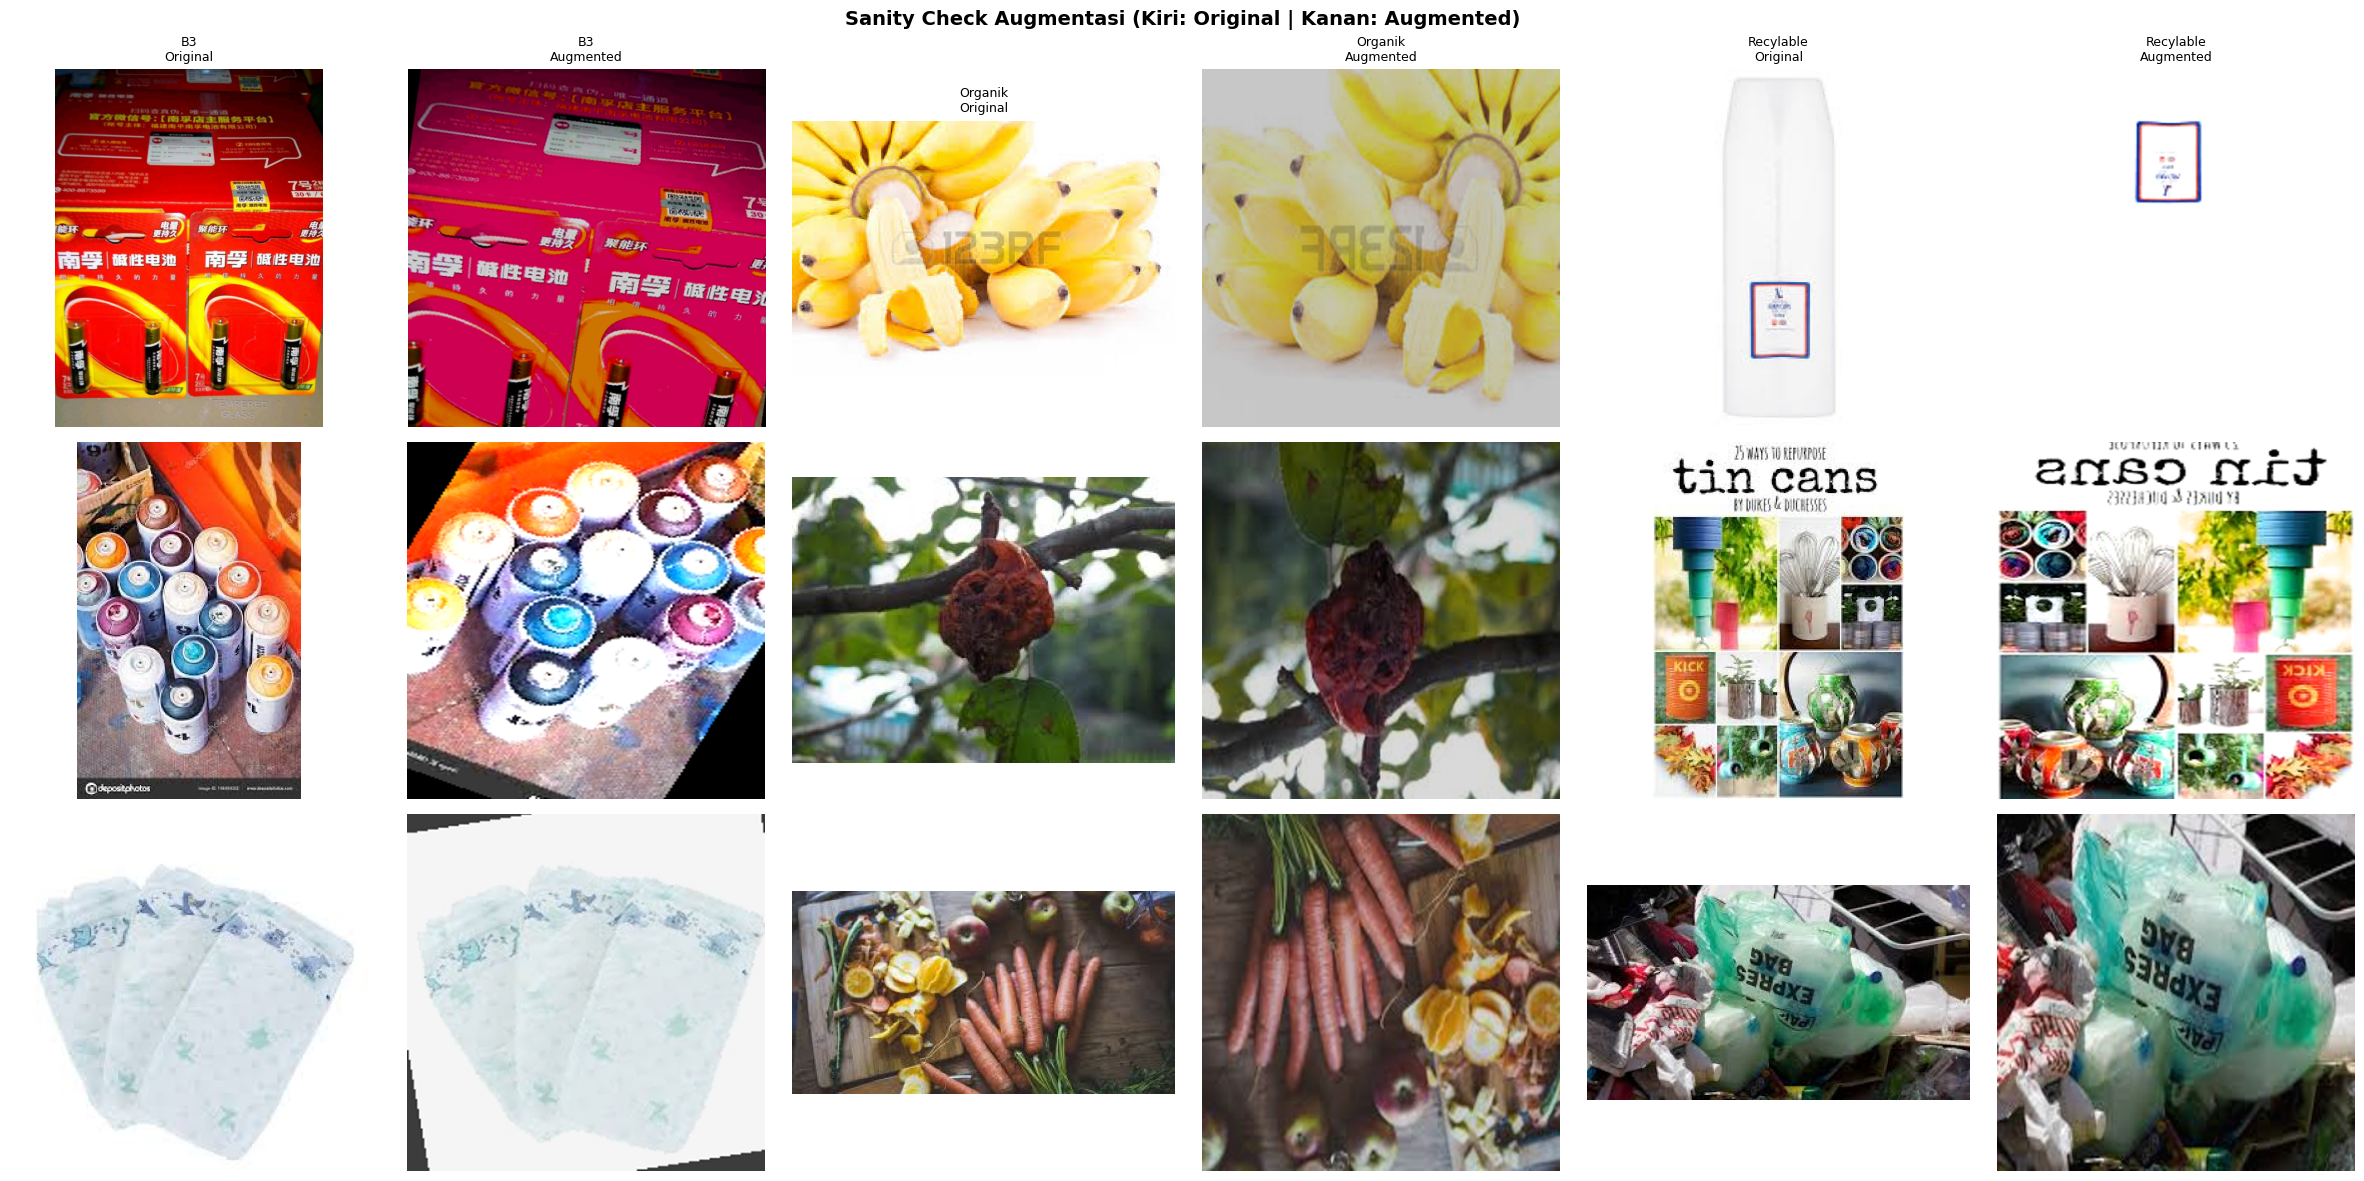

In [ ]:
def visualize_augmentations(df: pd.DataFrame, n_per_class: int = 3, save_path: str = None):
    """
    Plot contoh gambar per kelas:
    - Kolom kiri : gambar ASLI (versi bersih yang akan jadi view 0)
    - Kolom kanan: gambar setelah augmentasi train (seperti view 1..N_AUG)
    """
    classes = sorted(df['label'].unique())
    n_cols  = 2 * len(classes)
    fig, axes = plt.subplots(n_per_class, n_cols,
                             figsize=(4 * n_cols, 4 * n_per_class), squeeze=False)
    fig.suptitle('Sanity Check Augmentasi (Kiri: Original | Kanan: Augmented)',
                 fontsize=14, fontweight='bold')

    for col_offset, cls in enumerate(classes):
        pool   = df[df['label'] == cls]
        subset = pool.sample(n=min(n_per_class, len(pool)), random_state=RANDOM_SEED)
        aug_transform = build_aug('train', label=cls)

        for row_idx, (_, sample) in enumerate(subset.iterrows()):
            orig = load_image(sample['abs_path'])
            aug  = aug_transform(orig)

            ax_orig = axes[row_idx][col_offset * 2]
            ax_aug  = axes[row_idx][col_offset * 2 + 1]
            ax_orig.imshow(orig)
            ax_aug.imshow(aug)
            if row_idx == 0:
                ax_orig.set_title(f'{cls}\nOriginal', fontsize=9)
                ax_aug.set_title(f'{cls}\nAugmented', fontsize=9)
            for ax in (ax_orig, ax_aug):
                ax.axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches='tight')
        print(f'[OK] Visualisasi disimpan: {save_path}')
    plt.show()


visualize_augmentations(df_train, n_per_class=3,
                        save_path=os.path.join(HEAD_DIR, 'augmentation_sanity_check.png'))


---
# TAHAP 1 – Ekstraksi Embedding (dijalankan sekali)

Tiap gambar dibaca **sekali**, lalu dijadikan `1 + N_AUG` view:
view 0 = versi asli (hanya resize), view 1..N_AUG = versi teraugmentasi (hanya untuk split `train`;
kelas B3 memakai augmentasi yang lebih agresif). Val dan test hanya view 0.

Hasil per split disimpan di `EMBEDDING_DIR/embeddings_{split}.npz`:

| key | isi |
|---|---|
| `embeddings` | `float32 [M, 1152]` (pooler_output vision encoder) |
| `labels` | `int32 [M]` |
| `label_names` | `str [M]` |
| `paths` | `str [M]` (path absolut gambar asli) |
| `orig_idx` | `int32 [M]` (indeks baris di CSV; view dari gambar yang sama punya `orig_idx` sama → penting untuk CV agar tidak bocor) |
| `view_idx` | `int8 [M]` (0 = asli, ≥1 = augmentasi) |

Proses ini **aman terhadap disconnect**: hasil disimpan per potongan (`CHUNK_IMAGES` gambar). Kalau sesi putus,
jalankan ulang cell yang sama dan proses melanjutkan dari potongan terakhir. Split yang sudah selesai otomatis dilewati.


## CELL 8 – Definisi: Encoder, Dataset Multi-View, Fungsi Ekstraksi


In [ ]:
from transformers import SiglipVisionModel, SiglipImageProcessor

# Hanya butuh mean/std dari processor; resize sudah dilakukan build_aug (selalu keluar 384x384).
_proc = SiglipImageProcessor.from_pretrained(MODEL_CHECKPOINT)
to_tensor_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=_proc.image_mean, std=_proc.image_std),   # SigLIP: mean=std=0.5 -> range [-1, 1]
])
print(f'[OK] Processor: size={_proc.size} | mean={_proc.image_mean} | std={_proc.image_std}')


def load_vision_encoder() -> nn.Module:
    """SigLIP vision tower saja (tanpa text tower), dibekukan, fp16 jika USE_FP16 dan ada GPU."""
    dtype = torch.float16 if (USE_FP16 and device.type == 'cuda') else torch.float32
    m = SiglipVisionModel.from_pretrained(MODEL_CHECKPOINT)
    m = m.to(device=device, dtype=dtype).eval()
    for p in m.parameters():
        p.requires_grad = False
    print(f'[OK] Vision encoder dimuat | dtype={dtype} | device={device}')
    return m


class MultiViewDataset(Dataset):
    """
    Satu gambar dibaca sekali -> (1 + n_aug) view.
    view 0 = asli (resize saja); view 1.. = augmentasi train sesuai kelas.
    Return: (pixel_values [V, 3, H, W], label_idx, index_di_df)
    """
    def __init__(self, df: pd.DataFrame, n_aug: int, label_to_idx: dict):
        self.paths        = df['abs_path'].tolist()
        self.labels       = df['label'].tolist()
        self.n_aug        = n_aug
        self.label_to_idx = label_to_idx
        self.clean_tf     = build_aug('val')

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int):
        img   = load_image(self.paths[i])
        label = self.labels[i]
        views = [self.clean_tf(img)]
        current_n_aug = self.n_aug.get(label, 0) if isinstance(self.n_aug, dict) else self.n_aug
        if current_n_aug > 0:
            aug_tf = build_aug('train', label=label)
            views += [aug_tf(img) for _ in range(current_n_aug)]
        pv = torch.stack([to_tensor_norm(v) for v in views], dim=0)   # [V_i, 3, H, W]
        return pv, self.label_to_idx[label], i


def custom_collate_fn(batch):
    return batch


# ── Penyimpanan potongan (part) untuk resume ─────────────────
def save_part(parts_dir: str, start: int, emb, orig, view, n_images: int) -> None:
    tmp   = os.path.join(parts_dir, 'tmp_part.npz')       # tulis dulu ke file sementara ...
    final = os.path.join(parts_dir, f'part_{start:07d}.npz')
    np.savez(tmp, embeddings=emb, orig_idx=orig, view_idx=view, n_images=n_images)
    os.replace(tmp, final)                                 # ... lalu ganti nama (atomik) -> tidak ada part setengah jadi


def scan_parts(parts_dir: str, n_total: int) -> int:
    """Hitung berapa gambar asli yang sudah selesai dari part yang ada. Part tidak konsisten -> mulai ulang."""
    part_files = sorted(Path(parts_dir).glob('part_*.npz'))
    n_done = 0
    for pf in part_files:
        start = int(pf.stem.split('_')[1])
        try:
            with np.load(pf) as z:
                n_img = int(z['n_images'])
        except Exception:
            n_img = -1
        if start != n_done or n_img <= 0:
            print('  [WARN] Part tidak konsisten → split ini diproses ulang dari awal.')
            for p in part_files:
                p.unlink()
            return 0
        n_done += n_img
    if n_done > n_total:
        print('  [WARN] Jumlah part melebihi jumlah data (manifest berubah?) → proses ulang dari awal.')
        for p in part_files:
            p.unlink()
        return 0
    return n_done


def assemble_parts(parts_dir: str):
    E, O, V = [], [], []
    for pf in sorted(Path(parts_dir).glob('part_*.npz')):
        with np.load(pf) as z:
            E.append(z['embeddings']); O.append(z['orig_idx']); V.append(z['view_idx'])
    return np.concatenate(E), np.concatenate(O), np.concatenate(V)


def extract_split(df: pd.DataFrame, split_name: str, n_aug, vision_model: nn.Module) -> str:
    """Ekstrak embedding satu split -> EMBEDDING_DIR/embeddings_{split}.npz. Lewati jika sudah ada."""
    out_path = os.path.join(EMBEDDING_DIR, f'embeddings_{split_name}.npz')
    if os.path.exists(out_path):
        print(f'[SKIP] {split_name}: sudah ada → {out_path}')
        return out_path

    df        = df.reset_index(drop=True)
    N         = len(df)

    if isinstance(n_aug, dict):
        total_views_split = sum(1 + n_aug.get(lbl, 0) for lbl in df['label'])
    else:
        total_views_split = N * (1 + n_aug)

    parts_dir = os.path.join(EMBEDDING_DIR, f'_parts_{split_name}')
    os.makedirs(parts_dir, exist_ok=True)

    n_done = scan_parts(parts_dir, N)
    if n_done:
        print(f'[RESUME] {split_name}: {n_done}/{N} gambar sudah diproses, melanjutkan...')

    if n_done < N:
        ds     = MultiViewDataset(df.iloc[n_done:].reset_index(drop=True), n_aug, LABEL_TO_IDX)
        loader = DataLoader(
            ds, batch_size=BATCH_SIZE_EKSTRAKSI, shuffle=False,
            num_workers=NUM_WORKERS_EKSTRAKSI, pin_memory=(device.type == 'cuda'),
            prefetch_factor=(2 if NUM_WORKERS_EKSTRAKSI > 0 else None),
            collate_fn=custom_collate_fn
        )
        buf_e, buf_o, buf_v, buf_n = [], [], [], 0
        chunk_start = n_done

        def flush():
            nonlocal buf_e, buf_o, buf_v, buf_n, chunk_start
            if buf_n == 0:
                return
            save_part(parts_dir, chunk_start,
                      np.concatenate(buf_e), np.concatenate(buf_o), np.concatenate(buf_v), buf_n)
            chunk_start += buf_n
            buf_e, buf_o, buf_v, buf_n = [], [], [], 0

        for batch in tqdm(loader, desc=f'Ekstrak [{split_name}]', unit='batch'):
            all_pvs = torch.cat([item[0] for item in batch], dim=0)
            all_origs = []
            all_views = []
            for pv, _, idx in batch:
                v_i = pv.shape[0]
                all_origs.extend([idx] * v_i)
                all_views.extend(list(range(v_i)))

            chunk_size = BATCH_SIZE_EKSTRAKSI
            emb_list = []
            with torch.no_grad():
                for i in range(0, all_pvs.shape[0], chunk_size):
                    x = all_pvs[i:i+chunk_size].to(device=device, dtype=vision_model.dtype, non_blocking=True)
                    emb = vision_model(pixel_values=x).pooler_output
                    emb_list.append(emb.float().cpu())

            batch_emb = torch.cat(emb_list, dim=0).numpy()
            orig = np.array(all_origs, dtype=np.int32) + n_done

            buf_e.append(batch_emb)
            buf_o.append(orig)
            buf_v.append(np.array(all_views, dtype=np.int8))
            buf_n += len(batch)

            if buf_n >= CHUNK_IMAGES:
                flush()
        flush()

    E, O, Vw = assemble_parts(parts_dir)
    assert len(E) == total_views_split, f'Jumlah baris {len(E)} != {total_views_split} (Total views)'

    labels      = df['label'].map(LABEL_TO_IDX).to_numpy()[O]
    label_names = df['label'].to_numpy()[O]
    paths       = df['abs_path'].to_numpy()[O]
    np.savez_compressed(
        out_path,
        embeddings  = E.astype(np.float32),
        labels      = labels.astype(np.int32),
        label_names = label_names.astype(str),
        paths       = paths.astype(str),
        orig_idx    = O.astype(np.int32),
        view_idx    = Vw.astype(np.int8),
    )
    for p in Path(parts_dir).glob('*.npz'):
        p.unlink()
    Path(parts_dir).rmdir()
    print(f'[OK] embeddings_{split_name}.npz → shape={E.shape} ({N} gambar, total {total_views_split} views)')
    return out_path

print('[OK] Fungsi ekstraksi berhasil didefinisikan.')


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

[OK] Processor: size=SizeDict(height=384, width=384, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | mean=(0.5, 0.5, 0.5) | std=(0.5, 0.5, 0.5)
[OK] Fungsi ekstraksi berhasil didefinisikan.


## CELL 9 – Jalankan Ekstraksi (train → val → test)

Ini bagian yang lama, tetapi hanya perlu dijalankan **sekali**. Kalau sesi terputus, jalankan ulang cell ini
(mount Drive + Cell 2–8 dulu); ekstraksi akan melanjutkan.


In [ ]:
vision_model = load_vision_encoder()

for split_name, df_split, n_aug in [
    ('train', df_train, N_AUG),
    ('val',   df_val,   0),
    ('test',  df_test,  0),
]:
    extract_split(df_split, split_name, n_aug, vision_model)

# Catat metadata supaya jelas embedding ini dibuat dengan pengaturan apa
meta = {
    'model_checkpoint': MODEL_CHECKPOINT, 'image_size': IMAGE_SIZE, 'n_aug': N_AUG,
    'fp16': bool(USE_FP16 and device.type == 'cuda'), 'pooling': 'pooler_output',
    'label_to_idx': LABEL_TO_IDX,
    'n_images': {'train': len(df_train), 'val': len(df_val), 'test': len(df_test)},
}
with open(os.path.join(EMBEDDING_DIR, 'meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

# Backbone tidak dibutuhkan lagi -> bebaskan VRAM
del vision_model
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()
print('\n[OK] Tahap 1 selesai. Embedding tersimpan di:', EMBEDDING_DIR)


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/448 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-so400m-patch14-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...26}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...26}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.final_layer_norm.bias    

[OK] Vision encoder dimuat | dtype=torch.float16 | device=cuda
[SKIP] train: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5/embeddings_train.npz
[SKIP] val: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5/embeddings_val.npz
[SKIP] test: sudah ada → /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5/embeddings_test.npz

[OK] Tahap 1 selesai. Embedding tersimpan di: /content/drive/MyDrive/Senpro/embeddings/siglip-so400m-patch14-384_naug_2_2_5


---
# TAHAP 2 – Train Classifier (Head) di Atas Embedding

Bagian ini **tidak memanggil SigLIP sama sekali**. Di sesi baru cukup jalankan Cell 1–4 (mount Drive, config, GPU, import),
lalu cell-cell di bawah (Cell 5–9 tidak perlu).

| Cell | Isi |
|---|---|
| 10 | Load embedding `.npz` |
| 11–12 | Arsitektur head, loss, fungsi training/evaluasi (definisi saja) |
| 12b–12c | Diagnostik data: OOF (group `orig_idx`), label noise, near-duplicate, outlier |
| 13–15 | Train **satu** head sesuai `HEAD_TYPE` → kurva → evaluasi test |
| 16 | Bandingkan head neural (`HEADS_TO_COMPARE`) + kNN cosine |
| 17 | (lambat, opsional) SVM RBF dan LightGBM |
| 18 | Ensemble |
| 19 | Tabel perbandingan (metrik **val**, + val tanpa near-duplicate) + evaluasi test untuk pemenang |
| 20 | Error analysis di **val** (bukan test) + tetangga terdekat |

Pilih model berdasarkan metrik **val**. Test dipakai sekali di akhir untuk model yang sudah dipilih.


## CELL 10 – Load Embedding `.npz`

- `load_embeddings(split)` → dict: `embeddings`, `labels`, `label_names`, `paths`, `orig_idx`, `view_idx`
- `load_all_embeddings()` → `{'train': {...}, 'val': {...}, 'test': {...}}`
- `normalize=True` → L2-normalize (opsional, untuk cosine similarity / kNN / UMAP)


In [5]:
def _read_npz(path: str, allow_pickle: bool) -> dict:
    with np.load(path, allow_pickle=allow_pickle) as data:
        return {k: data[k] for k in data.files}


def load_embeddings(split: str, embedding_dir: str = None, normalize: bool = False) -> dict:
    """Muat embeddings_{split}.npz dari embedding_dir (default: EMBEDDING_DIR)."""
    embedding_dir = embedding_dir or EMBEDDING_DIR
    path = os.path.join(embedding_dir, f'embeddings_{split}.npz')
    if not os.path.exists(path):
        raise FileNotFoundError(f'{path} tidak ditemukan. Jalankan Tahap 1 (Cell 9) terlebih dulu.')

    try:
        out = _read_npz(path, allow_pickle=False)
    except ValueError:                        # file format lama (object array)
        out = _read_npz(path, allow_pickle=True)
        for k in ('label_names', 'paths'):
            out[k] = out[k].astype(str)

    emb = out['embeddings'].astype(np.float32)
    n   = len(emb)
    assert all(len(out[k]) == n for k in ('labels', 'label_names', 'paths')), \
        f'Panjang array tidak konsisten di {path}'

    if normalize:
        emb = emb / np.clip(np.linalg.norm(emb, axis=1, keepdims=True), 1e-12, None)
    out['embeddings'] = emb
    return out


def load_all_embeddings(splits=('train', 'val', 'test'), **kwargs) -> dict:
    return {s: load_embeddings(s, **kwargs) for s in splits}


emb_data = load_all_embeddings()

print('=== VERIFIKASI EMBEDDING ===')
for split, d in emb_data.items():
    dist = Counter(d['label_names'].tolist())
    n_img = len(np.unique(d['orig_idx'])) if 'orig_idx' in d else '?'
    print(f'\n  [{split}] embeddings={d["embeddings"].shape} dtype={d["embeddings"].dtype}'
          f' | gambar asli={n_img}')
    print(f'    distribusi baris : {dict(sorted(dist.items()))}')
    if 'view_idx' in d:
        print(f'    view             : {dict(sorted(Counter(d["view_idx"].tolist()).items()))}')


=== VERIFIKASI EMBEDDING ===

  [train] embeddings=(70599, 1152) dtype=float32 | gambar asli=21107
    distribusi baris : {'B3': 14556, 'Organik': 28860, 'Recylable': 27183}
    view             : {0: 21107, 1: 21107, 2: 21107, 3: 2426, 4: 2426, 5: 2426}

  [val] embeddings=(4523, 1152) dtype=float32 | gambar asli=4523
    distribusi baris : {'B3': 520, 'Organik': 2062, 'Recylable': 1941}
    view             : {0: 4523}

  [test] embeddings=(4524, 1152) dtype=float32 | gambar asli=4524
    distribusi baris : {'B3': 520, 'Organik': 2062, 'Recylable': 1942}
    view             : {0: 4524}


---
## CELL 11 – Class Weights & Arsitektur Head

`HEAD_TYPE` / `HEADS_TO_COMPARE` menerima:

| nama | bentuk |
|---|---|
| `linear` | 1152 → 3 (linear probe, baseline) |
| `mlp` | 1152 → 576 → 3, aktivasi + Dropout |
| `mlp_norm` | 1152 → 576 → **RMSNorm** → aktivasi → Dropout → 3 |
| `mlp2` | 1152 → 512 → 128 → 3 (2 tahap / bottleneck, tiap tahap: RMSNorm + aktivasi + Dropout) |
| `resmlp` | proyeksi 256 + 2 blok residual pre-norm (RMSNorm → Linear → aktivasi → Dropout → Linear) → 3 |

Aktivasi diatur `HEAD_ACT` (`gelu` atau `silu`).


In [6]:
import time

# ── Class weights (dari preprocessing) ────────────────────────
with open(CW_JSON) as f:
    class_weights_dict = json.load(f)

cw_tensor = torch.tensor(
    [class_weights_dict[lbl] for lbl in sorted(LABEL_TO_IDX, key=LABEL_TO_IDX.get)],
    dtype=torch.float32,
).to(device)
print('=== CLASS WEIGHTS ===')
for lbl, w in class_weights_dict.items():
    print(f'  {lbl}: {w:.4f}')
print(f'  Tensor (Recylable, Organik, B3): {cw_tensor.tolist()}\n')


# ── Blok arsitektur ────────────────────────────────────────────
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps    = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def make_act(name: str) -> nn.Module:
    return nn.SiLU() if name == 'silu' else nn.GELU()


class ResBlock(nn.Module):
    """Pre-norm residual: x + Linear(Dropout(act(Linear(RMSNorm(x)))))"""
    def __init__(self, width: int, dropout: float, act: str):
        super().__init__()
        self.norm = RMSNorm(width)
        self.fc1  = nn.Linear(width, 2 * width)
        self.act  = make_act(act)
        self.drop = nn.Dropout(dropout)
        self.fc2  = nn.Linear(2 * width, width)

    def forward(self, x):
        return x + self.fc2(self.drop(self.act(self.fc1(self.norm(x)))))


class ResMLPHead(nn.Module):
    def __init__(self, in_dim, num_classes, dropout=0.3, act='gelu', width=256, n_blocks=2):
        super().__init__()
        self.proj   = nn.Linear(in_dim, width)
        self.blocks = nn.Sequential(*[ResBlock(width, dropout, act) for _ in range(n_blocks)])
        self.norm   = RMSNorm(width)
        self.out    = nn.Linear(width, num_classes)

    def forward(self, x):
        return self.out(self.norm(self.blocks(self.proj(x))))


HEAD_TYPES = ('linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp')


def build_head(head_type: str, in_dim: int, num_classes: int,
               dropout: float = 0.3, act: str = 'gelu') -> nn.Module:
    if head_type == 'linear':
        m = nn.Linear(in_dim, num_classes)
    elif head_type == 'mlp':
        h = in_dim // 2
        m = nn.Sequential(nn.Linear(in_dim, h), make_act(act), nn.Dropout(dropout),
                          nn.Linear(h, num_classes))
    elif head_type == 'mlp_norm':
        h = in_dim // 2
        m = nn.Sequential(nn.Linear(in_dim, h), RMSNorm(h), make_act(act), nn.Dropout(dropout),
                          nn.Linear(h, num_classes))
    elif head_type == 'mlp2':
        m = nn.Sequential(nn.Linear(in_dim, 512), RMSNorm(512), make_act(act), nn.Dropout(dropout),
                          nn.Linear(512, 128),    RMSNorm(128), make_act(act), nn.Dropout(dropout),
                          nn.Linear(128, num_classes))
    elif head_type == 'resmlp':
        m = ResMLPHead(in_dim, num_classes, dropout, act)
    else:
        raise ValueError(f'head_type tidak dikenal: {head_type!r}. Pilih salah satu dari {HEAD_TYPES}')

    for mod in m.modules():
        if isinstance(mod, nn.Linear):
            nn.init.xavier_uniform_(mod.weight)
            nn.init.zeros_(mod.bias)
    return m


class FocalLoss(nn.Module):
    """FL(pt) = -alpha_t * (1 - pt)^gamma * log(pt). Alternatif CrossEntropy.
    v2: pt dihitung dari CE TANPA bobot (versi lama exp(-w*ce) bukan probabilitas kelas benar
    untuk kelas berbobot != 1, sehingga modulasi B3 salah)."""
    def __init__(self, weight: torch.Tensor = None, gamma: float = 2.0, label_smoothing: float = 0.0):
        super().__init__()
        self.gamma, self.weight, self.ls = gamma, weight, label_smoothing

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none',
                             label_smoothing=self.ls)
        pt = torch.exp(-F.cross_entropy(logits, targets, reduction='none'))
        return ((1 - pt) ** self.gamma * ce).mean()


def make_criterion() -> nn.Module:
    # cw_tensor dibaca saat dipanggil -> ikut CLASS_WEIGHT_MODE yang diterapkan di Cell 12
    return (FocalLoss(weight=cw_tensor, gamma=FOCAL_GAMMA, label_smoothing=LABEL_SMOOTHING) if USE_FOCAL_LOSS
            else nn.CrossEntropyLoss(weight=cw_tensor, label_smoothing=LABEL_SMOOTHING))


# ── Normalisasi input (statistik dihitung dari TRAIN saja) ────
def fit_input_norm(X_train: np.ndarray, mode: str) -> dict:
    if mode == 'standardize':
        return {'mode': mode,
                'mu': X_train.mean(0).astype(np.float32),
                'sd': (X_train.std(0) + 1e-6).astype(np.float32)}
    return {'mode': mode}


def apply_input_norm(X: np.ndarray, norm: dict) -> np.ndarray:
    X = X.astype(np.float32)
    if norm['mode'] == 'l2':
        X = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)
    elif norm['mode'] == 'standardize':
        X = (X - norm['mu']) / norm['sd']
    return X


print(f'[OK] Arsitektur head: {HEAD_TYPES} | aktivasi: {HEAD_ACT}')


=== CLASS WEIGHTS ===
  Organik: 0.7313
  Recylable: 0.7765
  B3: 2.9000
  Tensor (Recylable, Organik, B3): [0.7765250205993652, 0.7313249707221985, 2.8999810218811035]

[OK] Arsitektur head: ('linear', 'mlp', 'mlp_norm', 'mlp2', 'resmlp') | aktivasi: gelu


---
## CELL 12 – Data ke GPU, Fungsi Training/Evaluasi, Registry Hasil


In [7]:
set_seed(RANDOM_SEED)

# ── (Opsional) buang baris TRAIN hasil review manual ──────────
def _path_key(p) -> str:
    """Kunci pencocokan = '<folder_kelas>/<nama_file>' (tahan beda root / separator)."""
    parts = str(p).replace('\\', '/').split('/')
    return '/'.join(parts[-2:])


def apply_train_exclusion(d: dict, csv_path: str):
    """Buang semua view dari gambar yang tercantum di csv_path. Hanya untuk TRAIN.
    Bila CSV punya kolom 'keputusan', hanya baris 'buang' / 'relabel:*' yang dipakai (wajib review manual)."""
    if not csv_path:
        return d, 0
    ex = pd.read_csv(csv_path)
    col = 'path' if 'path' in ex.columns else ex.columns[0]
    if 'keputusan' in ex.columns:
        kep = ex['keputusan'].fillna('').astype(str).str.strip().str.lower()
        ex  = ex[kep.str.startswith('buang') | kep.str.startswith('relabel')]
        if ex.empty:
            print('  [WARN] Kolom keputusan kosong semua -> tidak ada yang dibuang. Isi dulu hasil review.')
    keys  = set(ex[col].map(_path_key))
    drop  = np.isin(np.array([_path_key(p) for p in d['paths']]), list(keys))
    n_img = len(np.unique(d['orig_idx'][drop])) if drop.any() else 0
    n     = len(drop)
    out   = {k: (v[~drop] if isinstance(v, np.ndarray) and v.ndim >= 1 and len(v) == n else v)
             for k, v in d.items()}
    return out, n_img


emb_data.setdefault('_train_full', emb_data['train'])        # simpan train lengkap (idempoten saat cell diulang)
emb_data['train'], n_excl = apply_train_exclusion(emb_data['_train_full'], TRAIN_EXCLUDE_CSV)
if TRAIN_EXCLUDE_CSV:
    print(f'[INFO] TRAIN_EXCLUDE_CSV: {n_excl} gambar train dibuang ({len(emb_data["_train_full"]["labels"]) - len(emb_data["train"]["labels"])} baris). Val/test tidak disentuh.')

# ── Class weight: 'effective' = N/(C*N_c) dari jumlah BARIS train (setelah oversampling N_AUG) ──
if CLASS_WEIGHT_MODE == 'effective':
    _cnt = np.bincount(emb_data['train']['labels'], minlength=NUM_CLASSES).astype(np.float64)
    cw_tensor = torch.tensor(_cnt.sum() / (NUM_CLASSES * np.clip(_cnt, 1, None)),
                             dtype=torch.float32, device=device)
print(f'[INFO] class weight ({CLASS_WEIGHT_MODE}) Recylable/Organik/B3: '
      f'{[round(w, 4) for w in cw_tensor.tolist()]}')

# ── Data: normalisasi lalu pindahkan ke GPU ────────────────────
norm = fit_input_norm(emb_data['train']['embeddings'], INPUT_NORM)

def to_dev(split):
    X = torch.from_numpy(apply_input_norm(emb_data[split]['embeddings'], norm)).to(device)
    y = torch.from_numpy(emb_data[split]['labels'].astype(np.int64)).to(device)
    return X, y

X_tr, y_tr = to_dev('train')
X_va, y_va = to_dev('val')
X_te, y_te = to_dev('test')
D = X_tr.shape[1]
print(f'[INFO] Train {tuple(X_tr.shape)} | Val {tuple(X_va.shape)} | Test {tuple(X_te.shape)} | input_norm={INPUT_NORM}')

# Catat konfigurasi run -> hasil bisa direproduksi & dibandingkan antar RUN_NAME
with open(os.path.join(HEAD_DIR, f'run_config_{RUN_NAME}.json'), 'w') as f:
    json.dump({
        'run_name': RUN_NAME, 'embedding_dir': EMBEDDING_DIR, 'input_norm': INPUT_NORM,
        'class_weight_mode': CLASS_WEIGHT_MODE, 'class_weights': cw_tensor.tolist(),
        'loss': 'focal' if USE_FOCAL_LOSS else 'ce', 'focal_gamma': FOCAL_GAMMA,
        'label_smoothing': LABEL_SMOOTHING, 'mixup_alpha': MIXUP_ALPHA,
        'lr': HEAD_LR, 'weight_decay': HEAD_WEIGHT_DECAY, 'dropout': DROPOUT_RATE,
        'batch_size': HEAD_BATCH_SIZE, 'epochs': HEAD_EPOCHS, 'patience': EARLY_STOP_PATIENCE,
        'train_exclude_csv': TRAIN_EXCLUDE_CSV, 'n_train_rows': int(len(X_tr)), 'seed': RANDOM_SEED,
    }, f, indent=2)


# ── Penjaga aturan "test disentuh sekali" ──────────────────────
_TEST_REPORTED = globals().get('_TEST_REPORTED', [])

def mark_test_use(name: str) -> None:
    if _TEST_REPORTED and name not in _TEST_REPORTED:
        print(f'[PERINGATAN METODOLOGI] Test sudah dipakai untuk {_TEST_REPORTED}. Melihat test untuk '
              f'model lain lalu memilih yang terbaik = seleksi model via test (hasil tidak sahih).')
    if name not in _TEST_REPORTED:
        _TEST_REPORTED.append(name)


# ── Path history / checkpoint per run ──────────────────────────
def head_paths(run_name: str):
    return (os.path.join(HEAD_DIR, f'history_{run_name}.json'),
            os.path.join(HEAD_DIR, f'best_head_{run_name}.pt'))

def save_history(history: dict, path: str) -> None:
    with open(path, 'w') as f:
        json.dump(history, f, indent=2)

def load_history(path: str) -> dict:
    with open(path) as f:
        return json.load(f)

def save_head(model, path: str, head_type: str) -> None:
    torch.save({
        'state_dict': model.state_dict(),
        'head_type': head_type, 'in_dim': D, 'num_classes': NUM_CLASSES,
        'dropout': DROPOUT_RATE, 'act': HEAD_ACT,
        'input_norm': {k: (torch.from_numpy(v) if isinstance(v, np.ndarray) else v) for k, v in norm.items()},
        'label_to_idx': LABEL_TO_IDX, 'model_checkpoint': MODEL_CHECKPOINT,
    }, path)

def load_head(path: str):
    """Muat head dari file .pt (arsitektur dibangun ulang dari metadata). Return (model, ckpt)."""
    ckpt = torch.load(path, map_location=device)
    m = build_head(ckpt['head_type'], ckpt['in_dim'], ckpt['num_classes'],
                   ckpt['dropout'], ckpt['act']).to(device)
    m.load_state_dict(ckpt['state_dict'])
    return m.eval(), ckpt


# ── Metrik ─────────────────────────────────────────────────────
def metrics_from_preds(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    out = {'acc': float((y_true == y_pred).mean()), 'macro_f1': float(f.mean())}
    for i in range(NUM_CLASSES):
        n = IDX_TO_LABEL[i]
        out[f'precision_{n}'], out[f'recall_{n}'], out[f'f1_{n}'] = float(p[i]), float(r[i]), float(f[i])
    return out


@torch.no_grad()
def predict_proba(model, X, batch_size: int = 4096) -> np.ndarray:
    model.eval()
    return torch.cat([torch.softmax(model(X[i:i + batch_size]), -1)
                      for i in range(0, len(X), batch_size)]).cpu().numpy()


@torch.no_grad()
def evaluate_head(model, X, y, criterion, batch_size=2048, return_preds=False):
    """loss + accuracy + precision/recall/F1 per kelas (dipakai untuk early stopping & history)."""
    model.eval()
    total_loss, all_preds = 0.0, []
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], y[i:i + batch_size]
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * len(xb)
        all_preds.append(logits.argmax(-1).cpu())
    preds  = torch.cat(all_preds).numpy()
    labels = y.cpu().numpy()

    m = metrics_from_preds(labels, preds)
    metrics = {'loss': total_loss / len(X), 'accuracy': m['acc']}
    for i in range(NUM_CLASSES):
        n = IDX_TO_LABEL[i]
        metrics[f'precision_{n}'] = round(m[f'precision_{n}'], 4)
        metrics[f'recall_{n}']    = round(m[f'recall_{n}'],    4)
        metrics[f'f1_{n}']        = round(m[f'f1_{n}'],        4)
    return (metrics, preds, labels) if return_preds else metrics


# ── Training ───────────────────────────────────────────────────
def train_one_epoch_head(model, X, y, optimizer, criterion, batch_size, mixup_alpha: float = 0.0):
    """Satu epoch. mixup_alpha > 0 -> mixup di ruang embedding (train_acc jadi perkiraan berbobot lambda)."""
    model.train()
    perm       = torch.randperm(len(X), device=X.device)
    total_loss = torch.zeros((), device=X.device)
    correct    = torch.zeros((), device=X.device)
    for i in range(0, len(X), batch_size):
        idx    = perm[i:i + batch_size]
        xb, yb = X[idx], y[idx]
        optimizer.zero_grad(set_to_none=True)
        if mixup_alpha > 0:
            lam    = float(np.random.beta(mixup_alpha, mixup_alpha))
            j      = torch.randperm(len(idx), device=X.device)
            logits = model(lam * xb + (1 - lam) * xb[j])
            loss   = lam * criterion(logits, yb) + (1 - lam) * criterion(logits, yb[j])
            pred   = logits.argmax(-1)
            correct += lam * (pred == yb).sum() + (1 - lam) * (pred == yb[j]).sum()
        else:
            logits = model(xb)
            loss   = criterion(logits, yb)
            correct += (logits.argmax(-1) == yb).sum()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.detach() * len(idx)
    return total_loss.item() / len(X), correct.item() / len(X)


def train_head(head_type: str, run_name: str, seed: int = None, verbose: bool = True) -> dict:
    """
    Train satu head dengan early stopping (val loss) + history JSON + simpan best head.
    Return dict: model (bobot terbaik), history, best_epoch, best_val_loss, params, seconds.
    """
    seed = RANDOM_SEED if seed is None else seed
    set_seed(seed)
    t0 = time.time()

    model     = build_head(head_type, D, NUM_CLASSES, DROPOUT_RATE, HEAD_ACT).to(device)
    criterion = make_criterion()
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HEAD_EPOCHS, eta_min=1e-6)
    n_params  = sum(p.numel() for p in model.parameters())
    hist_path, best_path = head_paths(run_name)

    history = {
        'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
        'val_recall_B3': [], 'val_precision_B3': [], 'val_f1_B3': [],
        'val_recall_Recylable': [], 'val_recall_Organik': [],
    }
    best_val_loss, best_epoch, no_improve = float('inf'), -1, 0

    if verbose:
        print(f'Head: {head_type} | act={HEAD_ACT} | params={n_params:,} | max {HEAD_EPOCHS} epoch | '
              f'batch={HEAD_BATCH_SIZE} | patience={EARLY_STOP_PATIENCE} | '
              f'loss={"focal" if USE_FOCAL_LOSS else "ce"} ls={LABEL_SMOOTHING} mixup={MIXUP_ALPHA}')
        print('=' * 78)

    for epoch in range(HEAD_EPOCHS):
        tr_loss, tr_acc = train_one_epoch_head(model, X_tr, y_tr, optimizer, criterion, HEAD_BATCH_SIZE, MIXUP_ALPHA)
        vm = evaluate_head(model, X_va, y_va, criterion)
        scheduler.step()

        history['train_loss'].append(round(tr_loss, 6));  history['train_acc'].append(round(tr_acc, 6))
        history['val_loss'].append(round(vm['loss'], 6)); history['val_acc'].append(round(vm['accuracy'], 6))
        history['val_recall_B3'].append(vm['recall_B3'])
        history['val_precision_B3'].append(vm['precision_B3'])
        history['val_f1_B3'].append(vm['f1_B3'])
        history['val_recall_Recylable'].append(vm['recall_Recylable'])
        history['val_recall_Organik'].append(vm['recall_Organik'])

        improved = vm['loss'] < best_val_loss
        if verbose:
            print(f'Ep {epoch+1:02d}/{HEAD_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc*100:5.2f}% | '
                  f'val loss {vm["loss"]:.4f} acc {vm["accuracy"]*100:5.2f}% | '
                  f'recall R/O/B3 {vm["recall_Recylable"]:.3f}/{vm["recall_Organik"]:.3f}/{vm["recall_B3"]:.3f}'
                  f'{"  ★" if improved else ""}')

        if improved:
            best_val_loss, best_epoch, no_improve = vm['loss'], epoch + 1, 0
            save_head(model, best_path, head_type)
            save_history(history, hist_path)
        else:
            no_improve += 1
            if no_improve >= EARLY_STOP_PATIENCE:
                if verbose:
                    print(f'\n[EARLY STOP] val_loss tidak turun selama {EARLY_STOP_PATIENCE} epoch → berhenti di epoch {epoch+1}.')
                break
        if (epoch + 1) % SAVE_EVERY_N_EPOCHS == 0:
            save_history(history, hist_path)

    save_history(history, hist_path)
    model.load_state_dict(torch.load(best_path, map_location=device)['state_dict'])   # kembali ke bobot terbaik
    model.eval()
    seconds = time.time() - t0
    if verbose:
        print(f'\n[OK] Selesai ({seconds:.0f}s). Best val_loss {best_val_loss:.4f} di epoch {best_epoch}')
        print(f'[OK] History : {hist_path}\n[OK] Best head: {best_path}')
    return {'model': model, 'history': history, 'best_epoch': best_epoch,
            'best_val_loss': best_val_loss, 'params': n_params, 'seconds': seconds}


# ── Registry hasil untuk perbandingan (metrik VAL) ─────────────
results = {}

def register_result(name, kind, val_probs=None, test_probs=None,
                    val_pred=None, test_pred=None, seconds=0.0, note=''):
    if val_probs  is not None: val_pred  = val_probs.argmax(1)
    if test_probs is not None: test_pred = test_probs.argmax(1)
    results[name] = {
        'kind': kind, 'val_probs': val_probs, 'test_probs': test_probs,
        'val_pred': val_pred, 'test_pred': test_pred, 'seconds': seconds, 'note': note,
        'val_metrics': metrics_from_preds(y_va.cpu().numpy(), val_pred),
    }

def fmt_params(n: int) -> str:
    return f'{n/1e6:.2f}M' if n >= 1e6 else f'{n/1e3:.1f}K'

def register_neural(name, out):
    m = out['model']
    register_result(name, 'neural', predict_proba(m, X_va), predict_proba(m, X_te),
                    seconds=out['seconds'],
                    note=f'{fmt_params(out["params"])} param, best ep {out["best_epoch"]}')

print('[OK] Fungsi training, evaluasi, dan registry hasil siap.')


[INFO] class weight (effective) Recylable/Organik/B3: [0.8657, 0.8154, 1.6167]
[INFO] Train (70599, 1152) | Val (4523, 1152) | Test (4524, 1152) | input_norm=standardize
[OK] Fungsi training, evaluasi, dan registry hasil siap.


---
## CELL 12b – Diagnostik Data di Ruang Embedding (data cleaning)

Semua head sudah ~99%, jadi kenaikan berikutnya datang dari **data**. Cell ini hanya membaca embedding
(tanpa SigLIP) dan menulis CSV kandidat ke `DIAG_DIR`. Tidak ada gambar yang dihapus/direlabel otomatis.

1. **Near-duplicate lintas split** (train↔val, train↔test, val↔test; cosine setelah standardize+L2, statistik
   train). Dedup preprocessing hanya pixel-exact; duplikat "mirip" membuat skor val/test terlalu optimis.
   Hasil: `VAL_NODUP_MASK` (dipakai kolom `_nodup` di Cell 19). Pasangan dengan **label berbeda** = kandidat
   label noise yang kuat.
2. **Prediksi out-of-fold (OOF) di train**: `StratifiedGroupKFold` dengan group `orig_idx` (semua view
   augmentasi satu gambar selalu di fold yang sama → tidak bocor). Standardisasi dihitung per fold-train.
   Prediksi hanya untuk view 0. Hasil `oof_metrics` = estimasi generalisasi kedua selain val.
3. **Label noise (confident learning + kNN)**: gambar train yang OOF-nya yakin kelas lain
   (`p_pred ≥ rata-rata self-confidence kelas itu`). `bukti='OOF+kNN'` bila mayoritas kNN juga setuju → prioritas.
4. **Ambigu** (margin top-2 OOF kecil) dan **outlier centroid** kelas.

Alur tindak lanjut:
1. Buka `label_noise_candidates.csv`, tinjau gambarnya (Cell 12c), isi kolom `keputusan`: `buang`,
   `relabel:<Kelas>`, atau `ok`.
2. Eksperimen cepat: set `TRAIN_EXCLUDE_CSV` ke CSV itu + **ganti `RUN_NAME`**, jalankan ulang dari Cell 12.
   Bandingkan val (dan `_nodup`) sebelum/sesudah.
3. Bila membaik: terapkan permanen di `preprocessing_lokal.ipynb` (relabel / pindah ke `Dataset/duplicates_removed/`,
   termasuk near-duplicate lintas split), re-ekstrak ke `EMBEDDING_DIR` baru, update `documentation.md`.

Rerun aman: bila `label_noise_candidates.csv` sudah berisi keputusan, hasil baru ditulis ke `*_baru.csv`.


In [8]:
from sklearn.model_selection import StratifiedGroupKFold

LBL_NAMES = np.array([IDX_TO_LABEL[i] for i in range(NUM_CLASSES)])
full_tr   = emb_data['_train_full']                         # train lengkap (sebelum TRAIN_EXCLUDE_CSV)
E_all     = full_tr['embeddings'].astype(np.float32)
y_all     = full_tr['labels'].astype(np.int64)
g_all     = full_tr['orig_idx']
v_all     = full_tr['view_idx'] if 'view_idx' in full_tr else np.zeros(len(y_all), np.int8)
p_all     = full_tr['paths'].astype(str)
m0        = v_all == 0
i0        = np.where(m0)[0]                                  # 1 baris view 0 = 1 gambar
mu0, sd0  = E_all[m0].mean(0), E_all[m0].std(0) + 1e-6       # statistik dari TRAIN saja


def std_l2(X, mu=mu0, sd=sd0):
    Z = (X.astype(np.float32) - mu) / sd
    return Z / np.clip(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12, None)


@torch.no_grad()
def top_neighbors(Q, DB, k=1, exclude_self=False, chunk=2048):
    """Q, DB: numpy L2-normalized. Return (sim [Nq,k], idx [Nq,k]). exclude_self: Q identik dgn DB."""
    db, S, I = torch.from_numpy(DB).to(device), [], []
    for i in range(0, len(Q), chunk):
        s = torch.from_numpy(Q[i:i + chunk]).to(device) @ db.T
        if exclude_self:
            r = torch.arange(len(s), device=device)
            s[r, r + i] = -2.0
        ts, ti = s.topk(min(k, db.shape[0]), dim=1)
        S.append(ts.cpu()); I.append(ti.cpu())
    del db
    return torch.cat(S).numpy(), torch.cat(I).numpy()


def safe_write_csv(df: pd.DataFrame, name: str) -> str:
    """Jangan menimpa CSV yang sudah berisi keputusan review manual."""
    path = os.path.join(DIAG_DIR, name)
    if os.path.exists(path) and 'keputusan' in df.columns:
        old = pd.read_csv(path)
        if 'keputusan' in old.columns and old['keputusan'].fillna('').astype(str).str.strip().ne('').any():
            path = path.replace('.csv', '_baru.csv')
            print(f'  [INFO] {name} sudah berisi keputusan review -> hasil baru ke {os.path.basename(path)}')
    df.to_csv(path, index=False)
    return path


Z_tr0, y_tr0, p_tr0 = std_l2(E_all[i0]), y_all[i0], p_all[i0]
Z_sp = {s: std_l2(emb_data[s]['embeddings']) for s in ('val', 'test')}
y_sp = {s: emb_data[s]['labels'].astype(np.int64) for s in ('val', 'test')}
p_sp = {s: emb_data[s]['paths'].astype(str) for s in ('val', 'test')}
Z_sp['train'], y_sp['train'], p_sp['train'] = Z_tr0, y_tr0, p_tr0

# ── 1. Near-duplicate lintas split ────────────────────────────
dup_rows, nearest = [], {}
for q, d in [('val', 'train'), ('test', 'train'), ('test', 'val')]:
    s, ix = top_neighbors(Z_sp[q], Z_sp[d], k=1)
    s, ix = s[:, 0], ix[:, 0]
    nearest[(q, d)] = s
    for j in np.where(s >= NEAR_DUP_COS)[0]:
        t = ix[j]
        dup_rows.append({'split': q, 'label': LBL_NAMES[y_sp[q][j]], 'path': p_sp[q][j],
                         'match_split': d, 'match_label': LBL_NAMES[y_sp[d][t]], 'match_path': p_sp[d][t],
                         'cosine': round(float(s[j]), 4), 'label_konflik': bool(y_sp[q][j] != y_sp[d][t])})
    qs = np.quantile(s, [0.5, 0.9, 0.99])
    print(f'[near-dup] {q:4s} vs {d:5s}: {int((s >= NEAR_DUP_COS).sum()):4d} gambar >= {NEAR_DUP_COS} '
          f'| cos terdekat p50/p90/p99 = {qs[0]:.3f}/{qs[1]:.3f}/{qs[2]:.3f}')
df_dup = pd.DataFrame(dup_rows, columns=['split', 'label', 'path', 'match_split', 'match_label',
                                         'match_path', 'cosine', 'label_konflik'])
df_dup = df_dup.sort_values(['label_konflik', 'cosine'], ascending=[False, False])
df_dup.to_csv(os.path.join(DIAG_DIR, 'cross_split_near_duplicates.csv'), index=False)
VAL_NODUP_MASK = nearest[('val', 'train')] < NEAR_DUP_COS
print(f'  label berbeda di pasangan near-dup: {int(df_dup["label_konflik"].sum())}  <- kandidat label noise kuat')
print(f'  VAL_NODUP_MASK: {int(VAL_NODUP_MASK.sum())}/{len(VAL_NODUP_MASK)} gambar val dipakai untuk kolom _nodup')

# ── 2. OOF di train (StratifiedGroupKFold, group = orig_idx) ──
def fit_fold_head(X, y, seed):
    set_seed(seed)
    cnt   = np.bincount(y.cpu().numpy(), minlength=NUM_CLASSES).astype(np.float64)
    w     = torch.tensor(cnt.sum() / (NUM_CLASSES * np.clip(cnt, 1, None)), dtype=torch.float32, device=device)
    model = build_head(OOF_HEAD, X.shape[1], NUM_CLASSES, DROPOUT_RATE, HEAD_ACT).to(device)
    crit  = nn.CrossEntropyLoss(weight=w, label_smoothing=LABEL_SMOOTHING)
    opt   = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WEIGHT_DECAY)
    sch   = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=OOF_EPOCHS, eta_min=1e-6)
    for _ in range(OOF_EPOCHS):
        train_one_epoch_head(model, X, y, opt, crit, HEAD_BATCH_SIZE, MIXUP_ALPHA)
        sch.step()
    return model.eval()


oof  = np.full((len(y_all), NUM_CLASSES), np.nan, np.float32)
sgkf = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
t0   = time.time()
for f, (tr_rows, ho_rows) in enumerate(sgkf.split(E_all, y_all, groups=g_all)):
    assert not (set(g_all[tr_rows]) & set(g_all[ho_rows])), 'Leakage: orig_idx muncul di dua fold'
    mu_f = E_all[tr_rows].mean(0); sd_f = E_all[tr_rows].std(0) + 1e-6      # statistik fold-train saja
    Xf   = torch.from_numpy((E_all[tr_rows] - mu_f) / sd_f).to(device)
    yf   = torch.from_numpy(y_all[tr_rows]).to(device)
    mdl  = fit_fold_head(Xf, yf, seed=RANDOM_SEED + f)
    ho0  = ho_rows[m0[ho_rows]]
    oof[ho0] = predict_proba(mdl, torch.from_numpy((E_all[ho0] - mu_f) / sd_f).to(device))
    del Xf, yf, mdl
    print(f'[OOF] fold {f + 1}/{CV_FOLDS}: train {len(tr_rows)} baris | prediksi {len(ho0)} gambar | {time.time() - t0:.0f}s')
if device.type == 'cuda':
    torch.cuda.empty_cache()

P = oof[i0]
assert not np.isnan(P).any(), 'Ada gambar train tanpa prediksi OOF'
pred0       = P.argmax(1)
oof_metrics = metrics_from_preds(y_tr0, pred0)
print(f'\n[OOF] macro F1 {oof_metrics["macro_f1"]:.4f} | acc {oof_metrics["acc"]:.4f} | '
      f'recall B3 {oof_metrics["recall_B3"]:.4f} | prec B3 {oof_metrics["precision_B3"]:.4f}')
cm_oof = pd.DataFrame(confusion_matrix(y_tr0, pred0, labels=list(range(NUM_CLASSES))),
                      index=LBL_NAMES, columns=LBL_NAMES)
print(cm_oof)
cm_oof.to_csv(os.path.join(DIAG_DIR, 'oof_confusion.csv'))
pd.DataFrame({'path': p_tr0, 'label': LBL_NAMES[y_tr0],
              **{f'p_{LBL_NAMES[c]}': P[:, c].round(4) for c in range(NUM_CLASSES)}}
             ).to_csv(os.path.join(DIAG_DIR, 'oof_predictions_train.csv'), index=False)

# ── 3. Label noise: confident learning + kNN leave-one-out ────
thr    = np.array([P[y_tr0 == c, c].mean() for c in range(NUM_CLASSES)])   # self-confidence per kelas
p_lab  = P[np.arange(len(P)), y_tr0]
p_pred = P.max(1)
flag   = (pred0 != y_tr0) & (p_pred >= thr[pred0])

knn_s, knn_i = top_neighbors(Z_tr0, Z_tr0, k=KNN_K, exclude_self=True)
neigh        = y_tr0[knn_i]
frac_same    = (neigh == y_tr0[:, None]).mean(1)
knn_major    = np.stack([(neigh == c).sum(1) for c in range(NUM_CLASSES)], 1).argmax(1)
dup_in_train = knn_s[:, 0] >= NEAR_DUP_COS

df_all = pd.DataFrame({
    'path': p_tr0, 'label': LBL_NAMES[y_tr0], 'pred_oof': LBL_NAMES[pred0],
    'p_label': p_lab.round(4), 'p_pred': p_pred.round(4), 'skor': (p_pred - p_lab).round(4),
    'knn_frac_sama': frac_same.round(3), 'knn_mayoritas': LBL_NAMES[knn_major],
    'nn1_cos': knn_s[:, 0].round(4), 'nn1_label': LBL_NAMES[y_tr0[knn_i[:, 0]]],
})
df_noise = df_all[flag].copy()
df_noise['bukti'] = np.where(knn_major[flag] == pred0[flag], 'OOF+kNN', 'OOF saja')
df_noise = df_noise.sort_values(['bukti', 'skor'], ascending=[True, False])
df_noise['keputusan'] = ''                                    # isi manual: buang | relabel:<Kelas> | ok
noise_csv = safe_write_csv(df_noise, 'label_noise_candidates.csv')

# ── 4. Ambigu (margin kecil, tidak termasuk kandidat noise) & outlier centroid ──
Ps     = np.sort(P, 1)
margin = Ps[:, -1] - Ps[:, -2]
df_amb = df_all.assign(margin=margin.round(4))[~flag].sort_values('margin').head(200)
df_amb.to_csv(os.path.join(DIAG_DIR, 'ambiguous_samples.csv'), index=False)

out_rows = []
for c in range(NUM_CLASSES):
    idx_c = np.where(y_tr0 == c)[0]
    cen   = Z_tr0[idx_c].mean(0); cen /= np.linalg.norm(cen) + 1e-12
    cs    = Z_tr0[idx_c] @ cen
    for j in idx_c[np.argsort(cs)[:max(5, len(idx_c) // 100)]]:          # 1% terjauh per kelas
        out_rows.append({'path': p_tr0[j], 'label': LBL_NAMES[c], 'cos_ke_centroid': round(float(Z_tr0[j] @ cen), 4),
                         'pred_oof': LBL_NAMES[pred0[j]], 'p_label': round(float(p_lab[j]), 4)})
df_out = pd.DataFrame(out_rows).sort_values('cos_ke_centroid')
df_out.to_csv(os.path.join(DIAG_DIR, 'centroid_outliers.csv'), index=False)

# ── Ringkasan ─────────────────────────────────────────────────
print('\n================ RINGKASAN DIAGNOSTIK DATA ================')
print(f'Kandidat label noise train : {len(df_noise)} '
      f'(OOF+kNN: {int((df_noise["bukti"] == "OOF+kNN").sum())}) -> {os.path.basename(noise_csv)}')
print(df_noise.groupby(['label', 'pred_oof']).size().rename('jumlah').to_string())
print(f'  label asli B3 di kandidat: {int((df_noise["label"] == "B3").sum())}  <- prioritas review (Recall B3)')
print(f'Near-duplicate di dalam train (nn1 >= {NEAR_DUP_COS}): {int(dup_in_train.sum())} gambar '
      f'(label beda: {int((dup_in_train & (y_tr0[knn_i[:, 0]] != y_tr0)).sum())})')
print(f'Near-duplicate lintas split : {len(df_dup)} -> cross_split_near_duplicates.csv')
print(f'Sampel ambigu               : {len(df_amb)} -> ambiguous_samples.csv')
print(f'Outlier centroid            : {len(df_out)} -> centroid_outliers.csv')
print(f'\nSemua CSV di: {DIAG_DIR}')
print('Tindak lanjut: review Cell 12c -> isi kolom keputusan -> TRAIN_EXCLUDE_CSV + RUN_NAME baru -> bandingkan val.')


[near-dup] val  vs train:   54 gambar >= 0.97 | cos terdekat p50/p90/p99 = 0.707/0.885/0.977
[near-dup] test vs train:   56 gambar >= 0.97 | cos terdekat p50/p90/p99 = 0.708/0.883/0.978
[near-dup] test vs val  :    9 gambar >= 0.97 | cos terdekat p50/p90/p99 = 0.623/0.825/0.932
  label berbeda di pasangan near-dup: 0  <- kandidat label noise kuat
  VAL_NODUP_MASK: 4469/4523 gambar val dipakai untuk kolom _nodup
[OOF] fold 1/5: train 56505 baris | prediksi 4222 gambar | 25s
[OOF] fold 2/5: train 56460 baris | prediksi 4221 gambar | 47s
[OOF] fold 3/5: train 56379 baris | prediksi 4222 gambar | 65s
[OOF] fold 4/5: train 56556 baris | prediksi 4221 gambar | 80s
[OOF] fold 5/5: train 56496 baris | prediksi 4221 gambar | 96s

[OOF] macro F1 0.9883 | acc 0.9896 | recall B3 0.9913 | prec B3 0.9772
           Recylable  Organik    B3
Recylable       8966       60    35
Organik           82     9517    21
B3                17        4  2405

================ RINGKASAN DIAGNOSTIK DATA ==========

## CELL 12c – Tinjau Visual Kandidat Label Noise

Tiap baris: gambar kandidat (label asli → prediksi OOF) + `TOP_K` tetangga terdekat di train (view 0, label
tetangga ditampilkan). Gunakan untuk mengisi kolom `keputusan` di `label_noise_candidates.csv`.
`FILTER_LABEL='B3'` untuk memprioritaskan kelas B3.


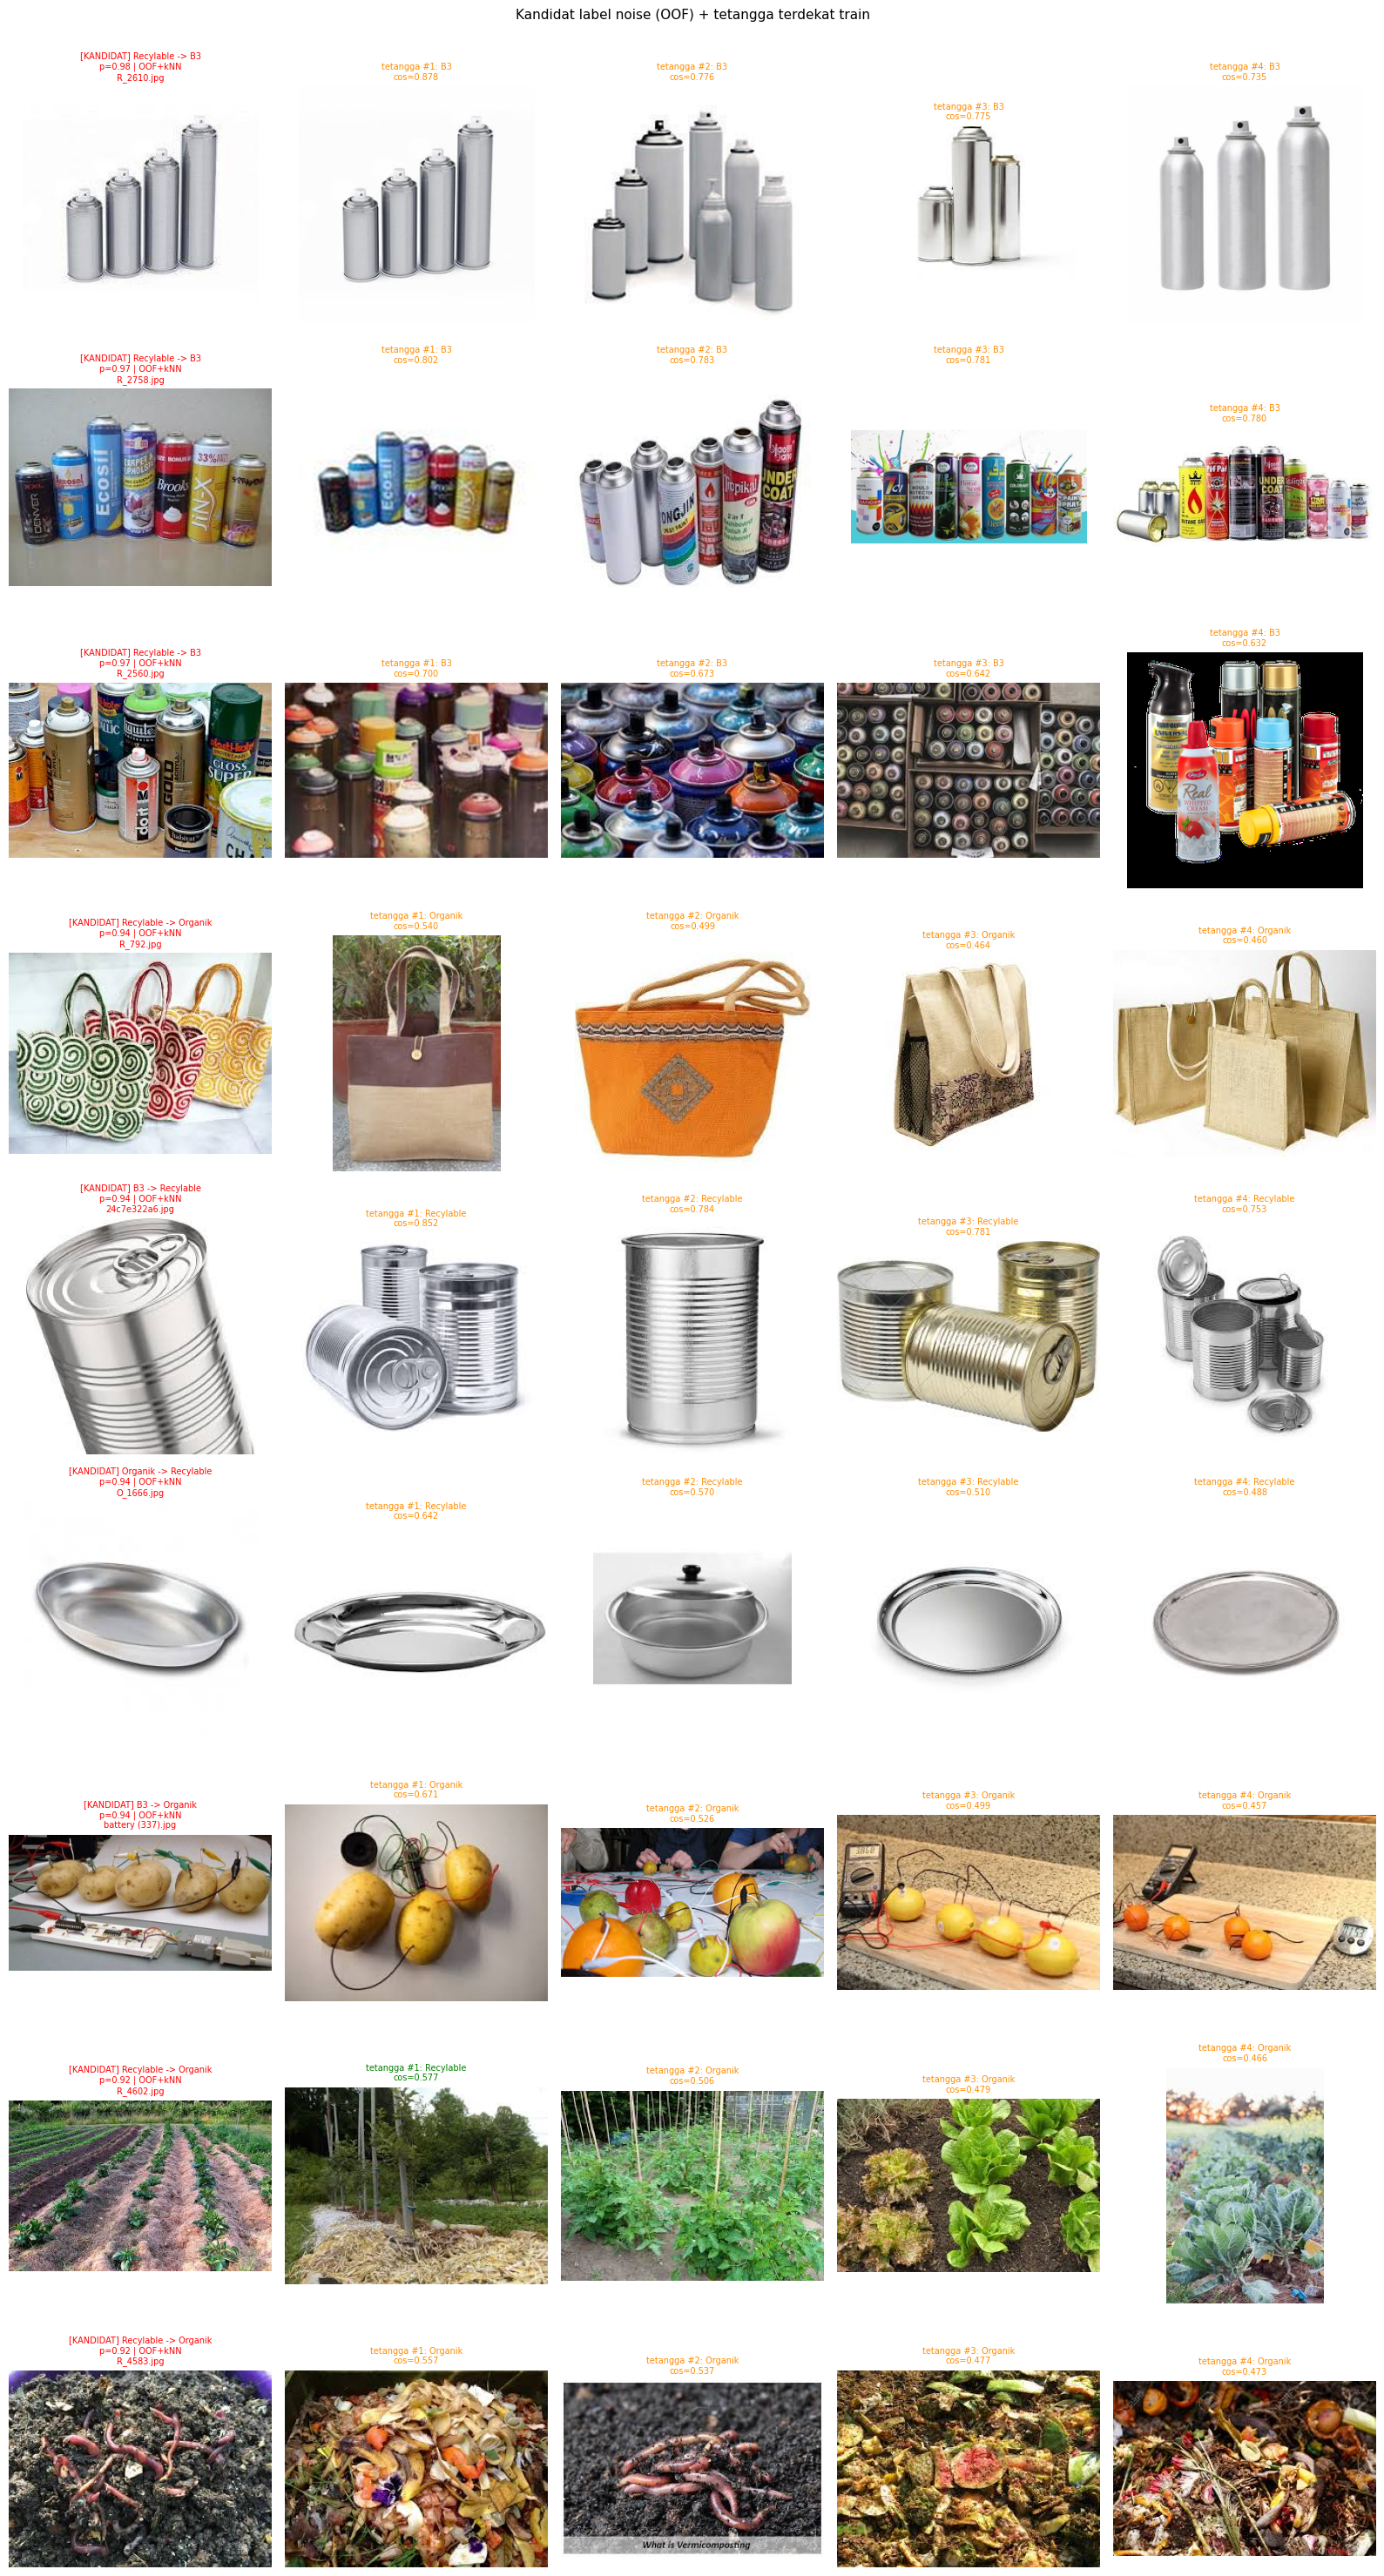

[OK] /content/drive/MyDrive/Senpro/data_diagnostics/siglip-so400m-patch14-384_naug_2_2_5/label_noise_review.png


In [9]:
from PIL import Image

N_SHOW_NOISE = 12
TOP_K_NOISE  = 4
FILTER_LABEL = None          # mis. 'B3' untuk review kelas B3 dulu


def _show_img(ax, path, title, color):
    try:
        img = Image.open(path); img.thumbnail((384, 384)); ax.imshow(img.convert('RGB'))
    except Exception:
        ax.text(0.5, 0.5, 'N/A', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title, fontsize=7, color=color); ax.axis('off')


sub = df_noise if FILTER_LABEL is None else df_noise[df_noise['label'] == FILTER_LABEL]
sub = sub.head(N_SHOW_NOISE)
if sub.empty:
    print('Tidak ada kandidat untuk ditampilkan.')
else:
    fig, axes = plt.subplots(len(sub), 1 + TOP_K_NOISE, figsize=(3.2 * (1 + TOP_K_NOISE), 3.3 * len(sub)),
                             squeeze=False)
    for row, (pos, r) in enumerate(sub.iterrows()):          # index df = posisi di array view 0
        _show_img(axes[row, 0], r['path'],
                  f"[KANDIDAT] {r['label']} -> {r['pred_oof']}\np={r['p_pred']:.2f} | {r['bukti']}\n"
                  f"{os.path.basename(r['path'])}", 'red')
        for col in range(TOP_K_NOISE):
            j = knn_i[pos, col]
            _show_img(axes[row, col + 1], p_tr0[j],
                      f'tetangga #{col + 1}: {LBL_NAMES[y_tr0[j]]}\ncos={knn_s[pos, col]:.3f}', 'green'
                      if y_tr0[j] == y_tr0[pos] else 'darkorange')
    plt.suptitle('Kandidat label noise (OOF) + tetangga terdekat train', fontsize=11, y=1.002)
    plt.tight_layout()
    fp = os.path.join(DIAG_DIR, f'label_noise_review{"_" + FILTER_LABEL if FILTER_LABEL else ""}.png')
    plt.savefig(fp, dpi=110, bbox_inches='tight'); plt.show()
    print(f'[OK] {fp}')


---
## CELL 13 – Train **Satu** Head (sesuai `HEAD_TYPE`)

Kalau langsung mau membandingkan semua arsitektur, lewati ke Cell 16.


In [ ]:
HISTORY_PATH, BEST_PATH = head_paths(RUN_NAME)

out     = train_head(HEAD_TYPE, RUN_NAME, seed=RANDOM_SEED, verbose=True)
model   = out['model']
history = out['history']


Head: mlp | act=gelu | params=665,859 | max 60 epoch | batch=256 | patience=8
Ep 01/60 | train loss 0.0300 acc 97.89% | val loss 0.0239 acc 98.32% | recall R/O/B3 0.980/0.985/0.989  ★
Ep 02/60 | train loss 0.0041 acc 99.55% | val loss 0.0221 acc 98.36% | recall R/O/B3 0.983/0.981/0.998  ★
Ep 03/60 | train loss 0.0028 acc 99.70% | val loss 0.0215 acc 98.59% | recall R/O/B3 0.987/0.983/0.996  ★
Ep 04/60 | train loss 0.0016 acc 99.84% | val loss 0.0274 acc 98.61% | recall R/O/B3 0.989/0.986/0.979
Ep 05/60 | train loss 0.0015 acc 99.86% | val loss 0.0237 acc 98.54% | recall R/O/B3 0.989/0.980/0.992
Ep 06/60 | train loss 0.0029 acc 99.72% | val loss 0.0329 acc 98.54% | recall R/O/B3 0.984/0.986/0.990
Ep 07/60 | train loss 0.0068 acc 99.57% | val loss 0.0417 acc 98.65% | recall R/O/B3 0.986/0.985/0.996
Ep 08/60 | train loss 0.0062 acc 99.53% | val loss 0.0450 acc 98.78% | recall R/O/B3 0.991/0.985/0.989
Ep 09/60 | train loss 0.0025 acc 99.83% | val loss 0.0444 acc 98.45% | recall R/O/B3 0.98

---
## CELL 14 – Plot Kurva Training (dari History JSON)


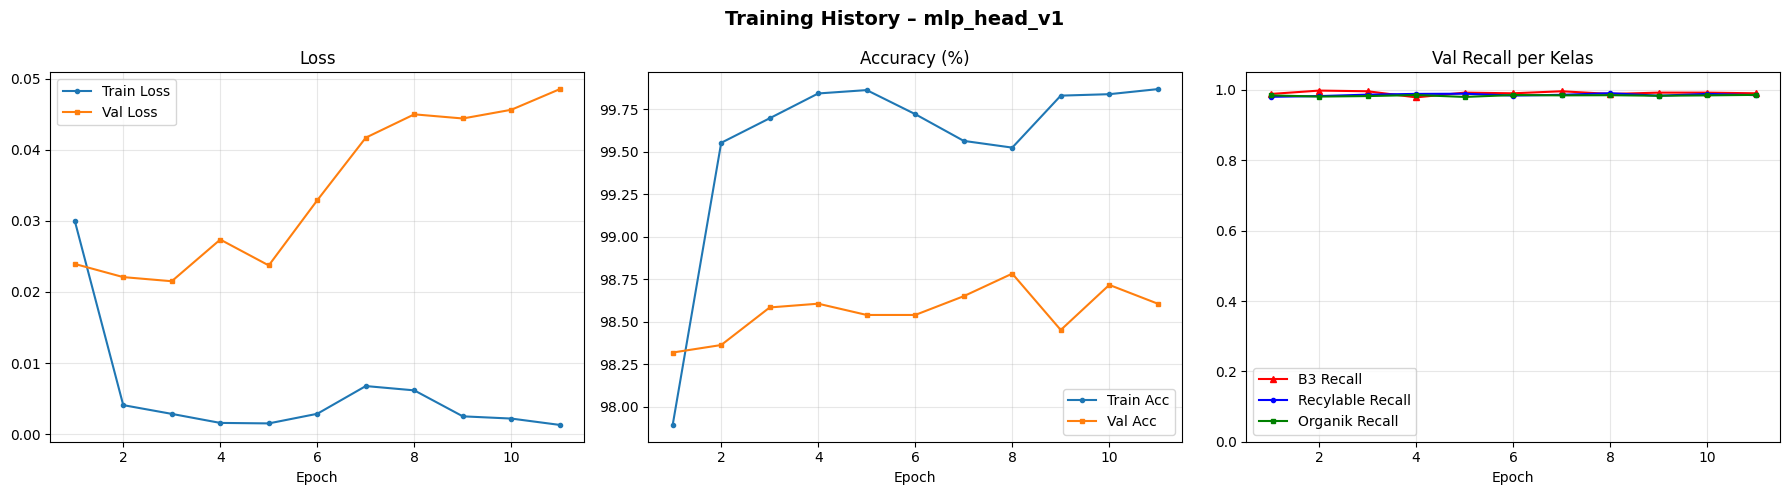

[OK] Kurva disimpan: /content/drive/MyDrive/Senpro/head_runs/training_curves_mlp_head_v1.png


In [ ]:
# Membaca dari file JSON di Drive -> bisa dijalankan kapan saja, walau sesi sudah terputus.
# (butuh Cell 2, 4, 11, 12 dijalankan lebih dulu; RUN_NAME menentukan file mana yang dibaca)
HISTORY_PATH, BEST_PATH = head_paths(RUN_NAME)
history = load_history(HISTORY_PATH)
x = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(x, history['train_loss'], label='Train Loss', marker='o', markersize=3)
axes[0].plot(x, history['val_loss'],   label='Val Loss',   marker='s', markersize=3)
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(x, [a*100 for a in history['train_acc']], label='Train Acc', marker='o', markersize=3)
axes[1].plot(x, [a*100 for a in history['val_acc']],   label='Val Acc',   marker='s', markersize=3)
axes[1].set_title('Accuracy (%)'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(x, history['val_recall_B3'],        label='B3 Recall',       marker='^', markersize=4, color='red')
axes[2].plot(x, history['val_recall_Recylable'], label='Recylable Recall', marker='o', markersize=3, color='blue')
axes[2].plot(x, history['val_recall_Organik'],   label='Organik Recall',   marker='s', markersize=3, color='green')
axes[2].set_title('Val Recall per Kelas'); axes[2].set_xlabel('Epoch'); axes[2].set_ylim(0, 1.05)
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Training History – {RUN_NAME}', fontsize=14, fontweight='bold')
plt.tight_layout()
curve_path = os.path.join(HEAD_DIR, f'training_curves_{RUN_NAME}.png')
plt.savefig(curve_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'[OK] Kurva disimpan: {curve_path}')


---
## CELL 15 – Evaluasi Test Set untuk Head dari Cell 13

Jalankan **hanya** bila head ini sudah dipilih sebagai model final berdasarkan val. Kalau masih membandingkan head (Cell 16–19), lewati cell ini; test cukup dilihat sekali di Cell 19.


In [ ]:
mark_test_use(f'single_{HEAD_TYPE}_{RUN_NAME}')
model, ckpt = load_head(BEST_PATH)
print(f'[OK] Best head ({ckpt["head_type"]}) dimuat dari: {BEST_PATH}')

criterion = make_criterion()
test_metrics, test_preds, test_labels = evaluate_head(model, X_te, y_te, criterion, return_preds=True)
label_names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print('\n=== EVALUASI TEST SET ===')
print(f'  Loss    : {test_metrics["loss"]:.4f}')
print(f'  Accuracy: {test_metrics["accuracy"]*100:.2f}%')
print('\n  Per kelas:')
for lname in label_names:
    print(f'    {lname:10s} | P={test_metrics[f"precision_{lname}"]:.4f} '
          f'| R={test_metrics[f"recall_{lname}"]:.4f} '
          f'| F1={test_metrics[f"f1_{lname}"]:.4f}')

print('\n=== CLASSIFICATION REPORT ===')
print(classification_report(test_labels, test_preds, target_names=label_names, zero_division=0))

print('=== CONFUSION MATRIX ===')
print(pd.DataFrame(confusion_matrix(test_labels, test_preds, labels=list(range(NUM_CLASSES))),
                   index=label_names, columns=label_names))


---
# Perbandingan Arsitektur Head

Semua model di bawah dilatih/dinilai di embedding yang sama. Tabel perbandingan (Cell 19) memakai metrik **val**.
Probabilitas test disimpan di belakang layar, tetapi tidak dipakai untuk memilih model.

## CELL 16 – Head Neural (`HEADS_TO_COMPARE`) + kNN Cosine

Tiap head dilatih dengan early stopping yang sama. kNN cosine dijalankan di GPU: vote tetangga terdekat
berbobot softmax(similarity / `KNN_TEMP`), lalu dikali class weight supaya kelas minoritas tidak kalah suara.


In [10]:
# ── Head neural ────────────────────────────────────────────────
for ht in HEADS_TO_COMPARE:
    print(f'[{ht:9s}] training...', end=' ', flush=True)
    out = train_head(ht, f'{RUN_NAME}__{ht}', seed=RANDOM_SEED, verbose=False)
    register_neural(ht, out)
    m = results[ht]['val_metrics']
    print(f'{out["seconds"]:4.0f}s | best ep {out["best_epoch"]:2d} | '
          f'val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


# ── kNN cosine (GPU) ───────────────────────────────────────────
@torch.no_grad()
def knn_probs(Xq, Xdb, ydb, k, temp, class_mult=None, chunk=1024):
    """Xq, Xdb sudah L2-normalized (tensor di device). Return prob numpy [Nq, C]."""
    k = min(k, len(Xdb))
    parts = []
    for i in range(0, len(Xq), chunk):
        sim = Xq[i:i + chunk] @ Xdb.T                              # cosine similarity
        top_s, top_i = sim.topk(k, dim=1)
        w = torch.softmax(top_s / temp, dim=1)                     # bobot tetangga
        votes = torch.zeros(len(top_s), NUM_CLASSES, device=Xq.device)
        votes.scatter_add_(1, ydb[top_i], w)
        parts.append(votes)
    p = torch.cat(parts)
    if class_mult is not None:
        p = p * class_mult
    return (p / p.sum(1, keepdim=True)).cpu().numpy()

def _l2(split):
    x = torch.from_numpy(emb_data[split]['embeddings']).to(device)
    return x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)

t0 = time.time()
Xdb = _l2('train')
register_result(
    'knn_cosine', 'knn',
    val_probs =knn_probs(_l2('val'),  Xdb, y_tr, KNN_K, KNN_TEMP, cw_tensor),
    test_probs=knn_probs(_l2('test'), Xdb, y_tr, KNN_K, KNN_TEMP, cw_tensor),
    seconds=time.time() - t0, note=f'k={KNN_K}, T={KNN_TEMP}, vote x class weight')
del Xdb
if device.type == 'cuda':
    torch.cuda.empty_cache()
m = results['knn_cosine']['val_metrics']
print(f'[knn_cosine] {results["knn_cosine"]["seconds"]:4.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


[linear   ] training...   48s | best ep 47 | val macroF1 0.9827 | recall B3 0.9904
[mlp      ] training...   20s | best ep 12 | val macroF1 0.9887 | recall B3 0.9942
[mlp_norm ] training...   26s | best ep 15 | val macroF1 0.9889 | recall B3 0.9923
[mlp2     ] training...   30s | best ep 15 | val macroF1 0.9901 | recall B3 0.9923
[resmlp   ] training...   45s | best ep 19 | val macroF1 0.9908 | recall B3 0.9923
[knn_cosine]    1s | val macroF1 0.9888 | recall B3 0.9942


---
## CELL 17 – (Lambat, Opsional) SVM RBF dan LightGBM

Berjalan di **CPU** (Colab gratis: 2 core), jadi paling lama di antara semua model. Matikan salah satunya dengan
`RUN_SVM = False` / `RUN_LGBM = False`.

- **SVM RBF** dilatih hanya pada baris *view asli* (tanpa augmentasi), karena SVM RBF melambat drastis seiring jumlah baris.
  `C` dipilih dari `SVM_C_GRID` berdasarkan macro F1 **val** (bukan test).
  Kalau masih terlalu lama, isi `SVM_MAX_ROWS` di Cell 2 (mis. 8000).
- **LightGBM** memakai semua baris, early stopping pada val, `class_weight='balanced'`. Karena val dipakai untuk early stopping, skor val LightGBM sedikit optimis.


In [11]:
RUN_SVM  = True
RUN_LGBM = True

ytr_np, yva_np = emb_data['train']['labels'], emb_data['val']['labels']

# ── SVM RBF ────────────────────────────────────────────────────
if RUN_SVM:
    try:
        from sklearn.svm import SVC
        from sklearn.model_selection import train_test_split

        view  = emb_data['train'].get('view_idx')
        mask0 = (view == 0) if view is not None else np.ones(len(ytr_np), dtype=bool)
        Xs = apply_input_norm(emb_data['train']['embeddings'][mask0], norm)
        ys = ytr_np[mask0]
        if SVM_MAX_ROWS and len(Xs) > SVM_MAX_ROWS:
            Xs, _, ys, _ = train_test_split(Xs, ys, train_size=SVM_MAX_ROWS,
                                            stratify=ys, random_state=RANDOM_SEED)
        Xva_s = apply_input_norm(emb_data['val']['embeddings'],  norm)
        Xte_s = apply_input_norm(emb_data['test']['embeddings'], norm)
        best_svm, t_all = None, time.time()
        for C in SVM_C_GRID:                                   # seleksi C via VAL
            print(f'[svm_rbf] C={C} | training pada {len(Xs)} baris... (bisa lama)', flush=True)
            svm = SVC(kernel='rbf', C=C, gamma='scale', class_weight='balanced').fit(Xs, ys)
            pv  = svm.predict(Xva_s)
            f1  = metrics_from_preds(yva_np, pv)['macro_f1']
            print(f'          val macroF1 {f1:.4f}')
            if best_svm is None or f1 > best_svm[0]:
                best_svm = (f1, C, svm, pv)
        _, C_best, svm, pv = best_svm
        register_result(
            'svm_rbf', 'sklearn', val_pred=pv, test_pred=svm.predict(Xte_s),
            seconds=time.time() - t_all,
            note=f'C={C_best} (grid {SVM_C_GRID} via val), {len(Xs)} baris view asli')
        m = results['svm_rbf']['val_metrics']
        print(f'[svm_rbf] C terbaik={C_best} | {results["svm_rbf"]["seconds"]:.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')
        del Xs, ys, svm, best_svm, Xva_s, Xte_s
    except Exception as e:
        print(f'[svm_rbf] GAGAL: {type(e).__name__}: {e}')

# ── LightGBM ───────────────────────────────────────────────────
if RUN_LGBM:
    try:
        try:
            import lightgbm as lgb
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'], check=True)
            import lightgbm as lgb

        Xtr_raw, Xva_raw, Xte_raw = (emb_data[s]['embeddings'] for s in ('train', 'val', 'test'))
        print(f'[lightgbm] training pada {len(Xtr_raw)} baris... (bisa lama)', flush=True)
        t0  = time.time()
        clf = lgb.LGBMClassifier(
            n_estimators=LGBM_MAX_TREES, learning_rate=0.05, num_leaves=31,
            colsample_bytree=0.3, subsample=0.8, subsample_freq=1,
            class_weight='balanced', n_jobs=-1, verbose=-1, random_state=RANDOM_SEED)
        clf.fit(Xtr_raw, ytr_np, eval_set=[(Xva_raw, yva_np)],
                callbacks=[lgb.early_stopping(30, verbose=False)])
        register_result(
            'lightgbm', 'sklearn',
            val_probs=clf.predict_proba(Xva_raw), test_probs=clf.predict_proba(Xte_raw),
            seconds=time.time() - t0, note=f'{getattr(clf, "best_iteration_", None)} pohon (early stop di val -> val sedikit optimis)')
        m = results['lightgbm']['val_metrics']
        print(f'[lightgbm] {results["lightgbm"]["seconds"]:.0f}s | val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')
        del clf
    except Exception as e:
        print(f'[lightgbm] GAGAL: {type(e).__name__}: {e}')


[svm_rbf] C=1.0 | training pada 21107 baris... (bisa lama)
          val macroF1 0.9894
[svm_rbf] C=3.0 | training pada 21107 baris... (bisa lama)
          val macroF1 0.9899
[svm_rbf] C=10.0 | training pada 21107 baris... (bisa lama)
          val macroF1 0.9897
[svm_rbf] C terbaik=3.0 | 303s | val macroF1 0.9899 | recall B3 0.9923
[lightgbm] training pada 70599 baris... (bisa lama)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[lightgbm] 232s | val macroF1 0.9837 | recall B3 0.9731


---
## CELL 18 – Ensemble

Rata-rata **probabilitas (softmax)**, bukan logit mentah, supaya head yang skalanya berbeda tetap sebanding.

- `ens_semua_head` : rata-rata semua head neural dari Cell 16.
- `ens_seed_<head>` : head neural terbaik (macro F1 val) dilatih ulang dengan beberapa seed (`ENSEMBLE_SEEDS`), lalu dirata-rata.
- `ens_lintas_model` : rata-rata `ens_seed_<head>` + kNN cosine + one-hot prediksi SVM (bila ada). Keluarga model berbeda membuat kesalahan berbeda, jadi rata-ratanya biasanya lebih stabil di data baru.


In [12]:
neural = [n for n in HEADS_TO_COMPARE if n in results and results[n]['kind'] == 'neural']
assert neural, 'Belum ada head neural di registry. Jalankan Cell 16 dulu.'

# (a) rata-rata semua head neural
register_result(
    'ens_semua_head', 'ensemble',
    val_probs =np.mean([results[n]['val_probs']  for n in neural], axis=0),
    test_probs=np.mean([results[n]['test_probs'] for n in neural], axis=0),
    note=f'rata-rata prob {len(neural)} head')

# (b) beberapa seed dari head neural terbaik
best_type = max(neural, key=lambda n: results[n]['val_metrics']['macro_f1'])
mem_val, mem_test, t0 = [results[best_type]['val_probs']], [results[best_type]['test_probs']], time.time()
print(f'[ens_seed] head terbaik: {best_type}')
for s in ENSEMBLE_SEEDS:
    if s == RANDOM_SEED:          # seed ini sudah dilatih di Cell 16
        continue
    print(f'  seed {s}...', end=' ', flush=True)
    out = train_head(best_type, f'{RUN_NAME}__{best_type}_s{s}', seed=s, verbose=False)
    mem_val.append(predict_proba(out['model'], X_va)); mem_test.append(predict_proba(out['model'], X_te))
    print(f'{out["seconds"]:.0f}s')

register_result(f'ens_seed_{best_type}', 'ensemble',
                val_probs=np.mean(mem_val, axis=0), test_probs=np.mean(mem_test, axis=0),
                seconds=time.time() - t0, note=f'{len(mem_val)} seed')
# (c) lintas keluarga model: MLP multi-seed + kNN + SVM (one-hot, SVC tidak punya prob tanpa CV mahal)
def _onehot(pred):
    return np.eye(NUM_CLASSES, dtype=np.float32)[pred]

fam_val, fam_test, fam_names = [results[f'ens_seed_{best_type}']['val_probs']], \
                               [results[f'ens_seed_{best_type}']['test_probs']], [f'ens_seed_{best_type}']
if 'knn_cosine' in results:
    fam_val.append(results['knn_cosine']['val_probs']); fam_test.append(results['knn_cosine']['test_probs'])
    fam_names.append('knn_cosine')
if 'svm_rbf' in results:
    fam_val.append(_onehot(results['svm_rbf']['val_pred'])); fam_test.append(_onehot(results['svm_rbf']['test_pred']))
    fam_names.append('svm_rbf')
if len(fam_names) > 1:
    register_result('ens_lintas_model', 'ensemble',
                    val_probs=np.mean(fam_val, axis=0), test_probs=np.mean(fam_test, axis=0),
                    note=' + '.join(fam_names))

for n in [x for x in ('ens_semua_head', f'ens_seed_{best_type}', 'ens_lintas_model') if x in results]:
    m = results[n]['val_metrics']
    print(f'[{n}] val macroF1 {m["macro_f1"]:.4f} | recall B3 {m["recall_B3"]:.4f}')


[ens_seed] head terbaik: resmlp
  seed 43... 56s
  seed 44... 56s
  seed 45... 33s
  seed 46... 39s
[ens_semua_head] val macroF1 0.9903 | recall B3 0.9923
[ens_seed_resmlp] val macroF1 0.9915 | recall B3 0.9942
[ens_lintas_model] val macroF1 0.9913 | recall B3 0.9942


---
## CELL 19 – Tabel Perbandingan (Val) + Evaluasi Test untuk Pemenang

Kolom: akurasi, macro F1, recall tiap kelas, precision dan F1 B3, waktu (detik). Urut dari macro F1 val tertinggi.
Kalau recall B3 lebih penting bagi Anda daripada macro F1, pilih dari kolom `recall_B3` (cek juga `prec_B3`, supaya
recall tinggi tidak dibeli dengan banyak salah alarm).

Kolom `macro_F1_nodup` / `recall_B3_nodup` = metrik val setelah membuang gambar val yang near-duplicate dengan train (Cell 12b). Selisih besar antara `macro_F1` dan `macro_F1_nodup` = skor val digelembungkan duplikat; pilih model yang tetap kuat di kolom `_nodup` karena itu lebih mewakili data baru.

Setelah memilih, jalankan `report_test('nama_model')` sekali untuk melihat hasil di test.


,model,tipe,acc,macro_F1,recall_Recylable,recall_Organik,recall_B3,prec_B3,F1_B3,macro_F1_nodup,recall_B3_nodup,detik,catatan
0,ens_seed_resmlp,ensemble,0.9916,0.9915,0.9938,0.9888,0.9942,0.9885,0.9914,0.9914,0.9940,183,5 seed
1,ens_lintas_model,ensemble,0.9907,0.9913,0.9928,0.9879,0.9942,0.9923,0.9933,0.9912,0.9940,0,ens_seed_resmlp + knn_cosine + svm_rbf
2,resmlp,neural,0.9909,0.9908,0.9912,0.9903,0.9923,0.9885,0.9904,0.9906,0.9920,45,"822.5K param, best ep 19"
3,ens_semua_head,ensemble,0.9903,0.9903,0.9923,0.9879,0.9923,0.9885,0.9904,0.9901,0.9920,0,rata-rata prob 5 head
4,mlp2,neural,0.9903,0.9901,0.9918,0.9884,0.9923,0.9866,0.9895,0.9899,0.9920,30,"657.0K param, best ep 15"
5,svm_rbf,sklearn,0.9892,0.9899,0.9897,0.9879,0.9923,0.9923,0.9923,0.9898,0.9920,303,"C=3.0 (grid [1.0, 3.0, 10.0] via val), 21107 b..."
6,mlp_norm,neural,0.9887,0.9889,0.9892,0.9874,0.9923,0.9866,0.9895,0.9887,0.9920,26,"666.4K param, best ep 15"
7,knn_cosine,knn,0.9889,0.9888,0.9902,0.9864,0.9942,0.9829,0.9885,0.9886,0.9940,1,"k=15, T=0.05, vote x class weight"
8,mlp,neural,0.9887,0.9887,0.9892,0.9869,0.9942,0.9829,0.9885,0.9885,0.9940,20,"665.9K param, best ep 12"
9,lightgbm,sklearn,0.9841,0.9837,0.9871,0.9840,0.9731,0.9922,0.9825,0.9834,0.9721,232,399 pohon (early stop di val -> val sedikit op...


[INFO] Estimasi generalisasi dari OOF train (mlp, 5-fold group orig_idx): macro F1 0.9883 | recall B3 0.9913 | prec B3 0.9772
[OK] Tabel disimpan: /content/drive/MyDrive/Senpro/head_runs/mlp_head_v2_ce_ls_mixup/perbandingan_head_mlp_head_v2_ce_ls_mixup.csv

macro F1 val tertinggi : ens_seed_resmlp
recall B3 val tertinggi: ens_seed_resmlp


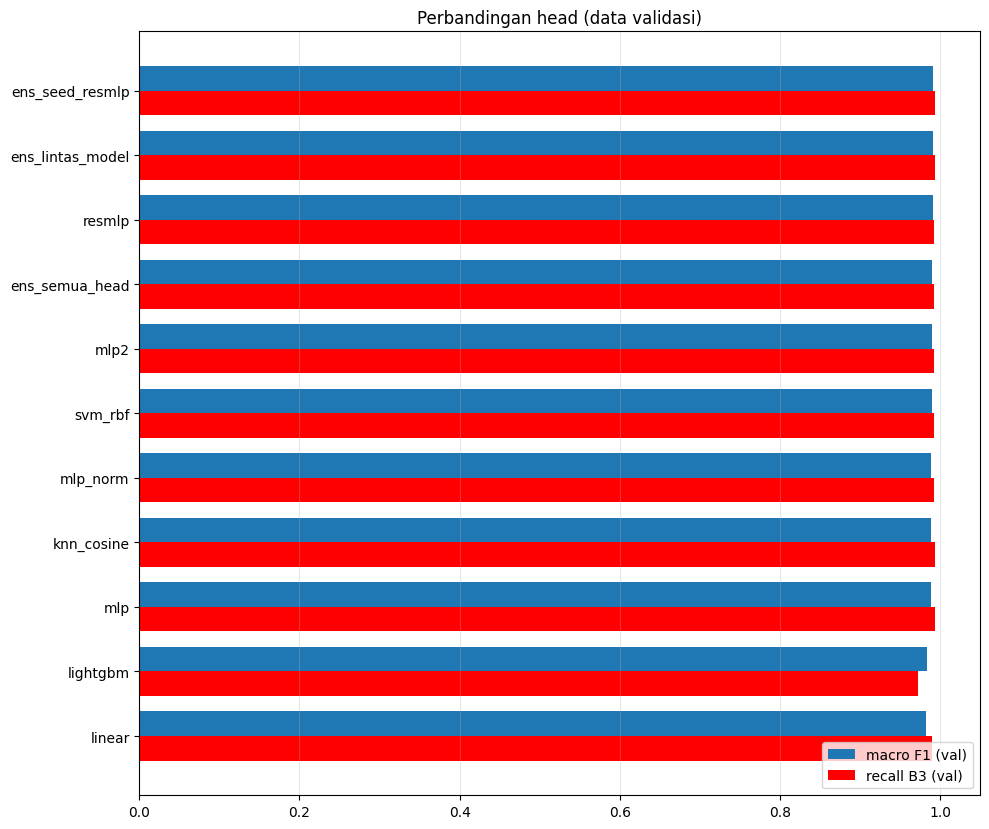

=== TEST: ens_seed_resmlp ===
              precision    recall  f1-score   support

   Recylable       0.99      0.99      0.99      1942
     Organik       1.00      0.99      1.00      2062
          B3       0.99      0.99      0.99       520

    accuracy                           0.99      4524
   macro avg       0.99      0.99      0.99      4524
weighted avg       0.99      0.99      0.99      4524

           Recylable  Organik   B3
Recylable       1930        7    5
Organik           13     2049    0
B3                 4        0  516


In [13]:
from IPython.display import display

def comparison_table() -> pd.DataFrame:
    nodup = globals().get('VAL_NODUP_MASK')               # dari Cell 12b (opsional)
    yv    = y_va.cpu().numpy()
    rows  = []
    for name, r in results.items():
        m = r['val_metrics']
        row = {
            'model': name, 'tipe': r['kind'],
            'acc': m['acc'], 'macro_F1': m['macro_f1'],
            'recall_Recylable': m['recall_Recylable'], 'recall_Organik': m['recall_Organik'],
            'recall_B3': m['recall_B3'], 'prec_B3': m['precision_B3'], 'F1_B3': m['f1_B3'],
        }
        if nodup is not None and len(nodup) == len(yv):
            mn = metrics_from_preds(yv[nodup], np.asarray(r['val_pred'])[nodup])
            row.update({'macro_F1_nodup': mn['macro_f1'], 'recall_B3_nodup': mn['recall_B3']})
        row.update({'detik': round(r['seconds']), 'catatan': r['note']})
        rows.append(row)
    return pd.DataFrame(rows).sort_values('macro_F1', ascending=False).reset_index(drop=True)


def report_test(name: str) -> None:
    mark_test_use(name)
    r, y = results[name], y_te.cpu().numpy()
    names = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]
    print(f'=== TEST: {name} ===')
    print(classification_report(y, r['test_pred'], target_names=names, zero_division=0))
    print(pd.DataFrame(confusion_matrix(y, r['test_pred'], labels=list(range(NUM_CLASSES))),
                       index=names, columns=names))


df_cmp = comparison_table()
display(df_cmp.round(4))
if 'oof_metrics' in globals():
    print(f"[INFO] Estimasi generalisasi dari OOF train ({OOF_HEAD}, {CV_FOLDS}-fold group orig_idx): "
          f"macro F1 {oof_metrics['macro_f1']:.4f} | recall B3 {oof_metrics['recall_B3']:.4f} | "
          f"prec B3 {oof_metrics['precision_B3']:.4f}")
csv_path = os.path.join(HEAD_DIR, f'perbandingan_head_{RUN_NAME}.csv')
df_cmp.to_csv(csv_path, index=False)
print(f'[OK] Tabel disimpan: {csv_path}')

best_f1 = df_cmp.iloc[0]['model']
best_b3 = df_cmp.loc[df_cmp['recall_B3'].idxmax(), 'model']
print(f'\nmacro F1 val tertinggi : {best_f1}')
print(f'recall B3 val tertinggi: {best_b3}')

# Grafik: macro F1 vs recall B3 (val)
fig, ax = plt.subplots(figsize=(10, 0.6 * len(df_cmp) + 1.8))
ypos, h = np.arange(len(df_cmp)), 0.38
ax.barh(ypos - h/2, df_cmp['macro_F1'],  h, label='macro F1 (val)')
ax.barh(ypos + h/2, df_cmp['recall_B3'], h, label='recall B3 (val)', color='red')
ax.set_yticks(ypos); ax.set_yticklabels(df_cmp['model']); ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.grid(axis='x', alpha=0.3); ax.legend(loc='lower right')
ax.set_title('Perbandingan head (data validasi)')
plt.tight_layout()
plt.savefig(os.path.join(HEAD_DIR, f'perbandingan_head_{RUN_NAME}.png'), dpi=120, bbox_inches='tight')
plt.show()

# Evaluasi test SEKALI untuk pemenang macro F1 (ganti nama kalau memilih berdasarkan kriteria lain)
report_test(best_f1)


---
## CELL 20 – Error Analysis di **Val** + Tetangga Terdekat (Train)

Versi lama menganalisis kesalahan di **test** lalu memakainya untuk membersihkan data. Itu membuat test ikut
"dilihat" saat mengambil keputusan, jadi test tidak lagi independen. Sekarang analisis memakai **val**
(dan untuk train, pakai kandidat OOF dari Cell 12b). Untuk tiap pasangan (label asli → prediksi) ditampilkan
gambar yang salah + `TOP_K` gambar train (view 0) terdekat dari kelas prediksi. Kesalahan disimpan ke
`val_errors_<model>.csv` di `HEAD_DIR`.

Catatan: perbaiki label val hanya bila jelas salah; jangan membuang sampel val yang "sulit" karena itu
menggelembungkan skor.


In [ ]:
from PIL import Image

ERR_MODEL  = globals().get('best_f1') or next(iter(results))   # default: pemenang macro F1 val (Cell 19)
ERR_PAIRS  = [('Recylable', 'Organik'), ('Organik', 'Recylable'), ('B3', 'Recylable'), ('B3', 'Organik')]
TOP_K      = 3
N_SHOW     = 10


def _l2n(X):
    return X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)


def _show(ax, path, title, color):
    try:
        img = Image.open(path); img.thumbnail((384, 384)); ax.imshow(img.convert('RGB'))
    except Exception:
        ax.text(0.5, 0.5, 'N/A', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(title, fontsize=7, color=color); ax.axis('off')


def error_analysis_val(model_name: str, true_lbl: str, pred_lbl: str, top_k=TOP_K, n_show=N_SHOW):
    r      = results[model_name]
    yv     = emb_data['val']['labels']
    pv     = np.asarray(r['val_pred'])
    pvpath = emb_data['val']['paths']
    miss   = np.where((yv == LABEL_TO_IDX[true_lbl]) & (pv == LABEL_TO_IDX[pred_lbl]))[0]
    print(f'[{model_name}] val {true_lbl} -> {pred_lbl}: {len(miss)} gambar')
    if len(miss) == 0:
        return

    tr     = emb_data['train']
    v0     = tr['view_idx'] == 0 if 'view_idx' in tr else np.ones(len(tr['labels']), bool)
    db_idx = np.where(v0 & (tr['labels'] == LABEL_TO_IDX[pred_lbl]))[0]
    db     = _l2n(apply_input_norm(tr['embeddings'][db_idx], norm))   # statistik norm dari train
    q      = _l2n(apply_input_norm(emb_data['val']['embeddings'][miss], norm))
    sim    = q @ db.T

    n_show = min(n_show, len(miss))
    fig, axes = plt.subplots(n_show, 1 + top_k, figsize=(3.2 * (1 + top_k), 3.2 * n_show), squeeze=False)
    for row in range(n_show):
        i = miss[row]
        _show(axes[row, 0], pvpath[i], f'[VAL] {true_lbl} -> {pred_lbl}\n{os.path.basename(pvpath[i])}', 'red')
        for col, j in enumerate(np.argsort(-sim[row])[:top_k], start=1):
            p = tr['paths'][db_idx[j]]
            _show(axes[row, col], p, f'train {pred_lbl} #{col}\nsim={sim[row, j]:.3f}\n{os.path.basename(p)}', 'green')
    plt.suptitle(f'Error analysis VAL – {model_name}: {true_lbl} -> {pred_lbl}', fontsize=11, y=1.002)
    plt.tight_layout()
    fp = os.path.join(HEAD_DIR, f'error_analysis_val_{model_name}_{true_lbl}_to_{pred_lbl}.png')
    plt.savefig(fp, dpi=110, bbox_inches='tight'); plt.show()
    print(f'  [OK] {fp}')


# Daftar semua kesalahan val untuk model terpilih
_r  = results[ERR_MODEL]
_yv = emb_data['val']['labels']; _pv = np.asarray(_r['val_pred'])
_err = np.where(_yv != _pv)[0]
df_err = pd.DataFrame({
    'path': emb_data['val']['paths'][_err],
    'label': [IDX_TO_LABEL[int(i)] for i in _yv[_err]],
    'pred':  [IDX_TO_LABEL[int(i)] for i in _pv[_err]],
})
if _r['val_probs'] is not None:
    df_err['p_pred'] = _r['val_probs'][_err, _pv[_err]].round(4)
df_err.to_csv(os.path.join(HEAD_DIR, f'val_errors_{ERR_MODEL}.csv'), index=False)
print(f'[OK] {len(df_err)} kesalahan val ({ERR_MODEL}) -> val_errors_{ERR_MODEL}.csv')
print(df_err.groupby(['label', 'pred']).size().rename('jumlah').to_string(), '\n')

for t, p in ERR_PAIRS:
    error_analysis_val(ERR_MODEL, t, p)
